# Part (a): Time-series EDA

Timestamp quality and temporal dependence shape both the preprocessing choices and the way forecasts can be evaluated. This chapter audits the Beijing Multi-Site Air Quality data, selects one station, and examines its training interval before any transformation is chosen. PM2.5 is the primary forecast target and PM10 the secondary one; the other variables give context and supply candidates for the Granger tests in the preprocessing chapter.

The analysis works on the measured hourly records with their native missing values. Gap-aware ACF and PACF preserve elapsed time, and a separate linear-interpolation comparison measures how much filling would change those diagnostics. The test interval contributes only timestamp and missingness counts. Forecasting, stationarity tests, decomposition, and Granger tests belong to the [preprocessing chapter](02_time_series_preprocessing.ipynb).


## Load the environment

The setup cell imports the shared paths and time-series helpers and records the package versions behind every displayed result. Nothing in this chapter draws random numbers; the seeded artificial gaps belong to the preprocessing chapter. The repository README describes how to install the environment.

In [1]:
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from preprocessing import RAW_DATA_DIR, OUTPUT_DIR
from preprocessing.time_series import (
    ar_information_criteria, compare_filled_dependence, gap_aware_acf, gap_aware_pacf,
    pacf_lag_order,
)

sns.set_theme(style="whitegrid")
package_versions = {name: version(name) for name in ["numpy", "pandas", "statsmodels", "matplotlib", "seaborn"]}
package_versions["python"] = platform.python_version()
print(f"Raw data directory: {RAW_DATA_DIR}")
display(pd.Series(package_versions, name="version").to_frame())


Raw data directory: D:\HCMUS\DataMining\preprocessing\data\raw


,version
numpy,2.5.5
pandas,3.1.1
statsmodels,0.15.0
matplotlib,3.11.2
seaborn,0.13.2
python,3.12.13


## Prepare data

The cell below downloads the archive from UCI, or reuses a local copy, and verifies its SHA-256 checksum, so the printed checksum identifies the exact source. It reads the 12 station files into `raw` with their values and row order unchanged, then builds `stations`, which adds a timestamp column for the audits that follow. The first run needs internet access, and the archive is stored under `RAW_DATA_DIR`, outside version control.


In [2]:
# The first download requires network access; later runs reuse the verified archive.
from preprocessing.air_quality import (
    AIR_QUALITY_SHA256, AIR_QUALITY_URL, add_timestamp, download_air_quality, read_stations,
)

archive_path = download_air_quality(RAW_DATA_DIR)
raw = read_stations(archive_path)
stations = add_timestamp(raw)
print(f"Archive SHA-256: {AIR_QUALITY_SHA256}")
print(raw.shape, raw["station"].nunique())


Archive SHA-256: b04da438b2f331ac0ffd45aebdfec0d20d2367feb5f6948c4b1f7ce1191e33c4
(420768, 18) 12


## Define variable roles

PM2.5 is the primary target: every preprocessing technique in the next chapter is applied to it and interpreted in full. PM10 is the secondary target; the same code runs on it with parameters fitted on its own training data, and its results appear in compact comparison tables. Because PM10 counts all particles up to 10 µm, it contains the PM2.5 fraction, so a strong association between the two targets is expected by definition rather than discovered.

The other numeric variables, SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN, and WSPM, enter this chapter's multivariate summaries and the next chapter's Granger tests, and they can serve as lagged forecast features. Wind direction `wd` is a categorical compass label that numeric tests cannot use directly, so the relationships section combines it with WSPM into wind components. The table below gives each variable's unit from the UCI description and defines the column lists that later audits reuse.

In [3]:
# Units as given in the UCI 501 variable description.
variable_roles = pd.DataFrame(
    [
        ("PM2.5", "primary target", "µg/m³"),
        ("PM10", "secondary target", "µg/m³"),
        ("SO2", "covariate", "µg/m³"),
        ("NO2", "covariate", "µg/m³"),
        ("CO", "covariate", "µg/m³"),
        ("O3", "covariate", "µg/m³"),
        ("TEMP", "covariate", "°C"),
        ("PRES", "covariate", "hPa"),
        ("DEWP", "covariate", "°C"),
        ("RAIN", "covariate", "mm"),
        ("WSPM", "covariate", "m/s"),
        ("wd", "categorical, converted to u/v", "compass label"),
        ("year/month/day/hour", "timestamp parts", "-"),
        ("No", "row identifier", "-"),
        ("station", "station identifier", "-"),
    ],
    columns=["variable", "role", "unit"],
)

TARGET_COLUMNS = ["PM2.5", "PM10"]
COVARIATE_COLUMNS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
POLLUTANT_COVARIATES = ["SO2", "NO2", "CO", "O3"]
WEATHER_COLUMNS = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
ANALYSIS_COLUMNS = TARGET_COLUMNS + COVARIATE_COLUMNS

# Fail early if the loaded frame lacks a column the later sections need.
missing_columns = sorted(set(ANALYSIS_COLUMNS + ["wd"]) - set(stations.columns))
assert not missing_columns, missing_columns

display(variable_roles)


,variable,role,unit
0,PM2.5,primary target,µg/m³
1,PM10,secondary target,µg/m³
2,SO2,covariate,µg/m³
3,NO2,covariate,µg/m³
4,CO,covariate,µg/m³
5,O3,covariate,µg/m³
6,TEMP,covariate,°C
7,PRES,covariate,hPa
8,DEWP,covariate,°C
9,RAIN,covariate,mm


## Select the station

The 12 stations share the city's weather but differ in pollutant levels and in where their records are missing. Parameters fitted on one station's training data, such as a Box-Cox $\lambda$, the lag order, or anomaly thresholds, would have to be refitted and checked before use at another station, so this chapter analyzes one station in depth and chooses it by data quality.

`audit_columns` runs `audit_stations` once per column. For each station it reports the record count, time span, file ordering, duplicate and absent timestamps, missing rate, the longest run of hours without a value, `long_gap_missing_share` (the fraction of missing hours that lie in gaps longer than 24 hours), and `long_gap_missing_hours` (the number of those hours). The audit covers every column the analysis uses: both targets, all Granger covariates, and `wd`, which the $u$ and $v$ wind components need. A station with complete PM2.5 records but long gaps in O3 or TEMP would weaken the multivariate sections.

The selection looks at gap length before missing rate. Isolated missing hours are easy to reconstruct, whereas interpolating across a long gap invents values, and the STL, Ljung-Box, and Granger implementations in the next chapter need filled, regularly spaced input; only the gap-aware ACF and PACF below can work with the gaps directly. Stations are ordered by three measures, lower being better, with each later measure used only to break ties:

1. Worst longest gap: the longest gap, in hours, in the worst audited column.
2. Mean `long_gap_missing_share` over the audited columns, which checks how much of the missingness lies in long gaps overall rather than in one event.
3. Mean missing rate over the audited columns.

These measures depend only on which hours are missing, never on pollutant values or model scores. The audit does span the full record, including test-period availability, so the choice is an exploratory data-quality decision rather than a prospectively evaluated procedure. Four alternative rules check whether the choice depends on this particular ordering. A monthly view of missing shares and a count of hours in which several stations lose PM2.5 together then show whether gaps cluster in time, which bears on the MCAR (missing completely at random) assumption behind the artificial gaps in the preprocessing chapter.


In [4]:
from preprocessing.air_quality import audit_columns

# wd is audited with the numeric columns because the u/v wind components need both wd and WSPM.
AUDIT_COLUMNS = ANALYSIS_COLUMNS + ["wd"]
LONG_GAP_HOURS = 24

station_audit = audit_columns(stations, AUDIT_COLUMNS, long_gap_hours=LONG_GAP_HOURS)

# Timestamp measures do not depend on the audited column, so one copy per station suffices.
timestamp_audit = station_audit.xs(AUDIT_COLUMNS[0], level="variable")[
    ["rows", "start", "end", "sorted", "duplicate_timestamps", "missing_timestamps"]
]
longest_gap_hours = station_audit["longest_target_gap_hours"].unstack("variable")[AUDIT_COLUMNS]
long_gap_share = station_audit["long_gap_missing_share"].unstack("variable")[AUDIT_COLUMNS]
missing_rate = station_audit["target_missing_rate"].unstack("variable")[AUDIT_COLUMNS]
hours_in_long_gaps = station_audit["long_gap_missing_hours"].unstack("variable")[AUDIT_COLUMNS]
# Every station shares one complete hourly grid, so stations differ only in missing values.
assert (timestamp_audit[["duplicate_timestamps", "missing_timestamps"]] == 0).all().all()
assert timestamp_audit[["rows", "start", "end"]].nunique().eq(1).all()

display(timestamp_audit)
print("Longest run of consecutive hours without a value:")
display(longest_gap_hours)
print(f"Share of missing hours that lie in gaps longer than {LONG_GAP_HOURS} hours:")
display(long_gap_share.round(3))
print("Missing rate (share of hourly records):")
display(missing_rate.round(4))


,rows,start,end,sorted,duplicate_timestamps,missing_timestamps
station,,,,,,
Aotizhongxin,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Changping,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Dingling,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Dongsi,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Guanyuan,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Gucheng,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Huairou,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Nongzhanguan,35064,2013-03-01,2017-02-28 23:00:00,True,0,0
Shunyi,35064,2013-03-01,2017-02-28 23:00:00,True,0,0


Longest run of consecutive hours without a value:


variable,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
station,,,,,,,,,,,,
Aotizhongxin,343,343,343,343,343,343,6,6,6,6,5,5
Changping,167,144,64,64,175,64,6,6,6,6,5,5
Dingling,72,43,48,44,1051,262,6,6,6,6,5,5
Dongsi,58,57,57,900,1517,57,6,6,6,6,5,5
Guanyuan,71,44,103,103,441,103,6,6,6,6,5,5
Gucheng,54,25,61,66,349,260,7,7,7,6,5,7
Huairou,208,208,207,207,211,207,6,6,6,6,5,13
Nongzhanguan,56,55,55,55,147,55,6,6,6,6,5,5
Shunyi,197,38,95,423,749,497,6,6,6,6,5,6


Share of missing hours that lie in gaps longer than 24 hours:


variable,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
station,,,,,,,,,,,,
Aotizhongxin,0.497,0.602,0.605,0.484,0.540,0.379,0.0,0.0,0.0,0.0,0.0,0.0
Changping,0.456,0.407,0.247,0.232,0.317,0.257,0.0,0.0,0.0,0.0,0.0,0.0
Dingling,0.257,0.125,0.182,0.070,0.589,0.341,0.0,0.0,0.0,0.0,0.0,0.0
Dongsi,0.351,0.351,0.296,0.756,0.805,0.295,0.0,0.0,0.0,0.0,0.0,0.0
Guanyuan,0.326,0.200,0.310,0.381,0.601,0.237,0.0,0.0,0.0,0.0,0.0,0.0
Gucheng,0.122,0.066,0.250,0.262,0.493,0.432,0.0,0.0,0.0,0.0,0.0,0.0
Huairou,0.403,0.494,0.416,0.292,0.354,0.386,0.0,0.0,0.0,0.0,0.0,0.0
Nongzhanguan,0.089,0.125,0.123,0.204,0.378,0.109,0.0,0.0,0.0,0.0,0.0,0.0
Shunyi,0.405,0.119,0.354,0.420,0.454,0.408,0.0,0.0,0.0,0.0,0.0,0.0


Missing rate (share of hourly records):


variable,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
station,,,,,,,,,,,,
Aotizhongxin,0.0264,0.0205,0.0267,0.0292,0.0507,0.0490,0.0006,0.0006,0.0006,0.0006,0.0004,0.0023
Changping,0.0221,0.0166,0.0179,0.0190,0.0434,0.0172,0.0015,0.0014,0.0015,0.0015,0.0012,0.0040
Dingling,0.0222,0.0187,0.0208,0.0352,0.0574,0.0346,0.0015,0.0014,0.0015,0.0015,0.0012,0.0040
Dongsi,0.0214,0.0158,0.0189,0.0457,0.0912,0.0189,0.0006,0.0006,0.0006,0.0006,0.0004,0.0022
Guanyuan,0.0176,0.0122,0.0135,0.0188,0.0500,0.0335,0.0006,0.0006,0.0006,0.0006,0.0004,0.0023
Gucheng,0.0184,0.0109,0.0145,0.0191,0.0400,0.0208,0.0015,0.0014,0.0015,0.0012,0.0012,0.0045
Huairou,0.0272,0.0222,0.0279,0.0467,0.0406,0.0328,0.0015,0.0015,0.0015,0.0016,0.0014,0.0086
Nongzhanguan,0.0179,0.0125,0.0127,0.0197,0.0344,0.0144,0.0006,0.0006,0.0006,0.0006,0.0004,0.0022
Shunyi,0.0260,0.0156,0.0370,0.0389,0.0621,0.0425,0.0015,0.0015,0.0015,0.0015,0.0013,0.0138


In [5]:
SELECTION_ORDER = ["worst_longest_gap_hours", "mean_long_gap_missing_share", "mean_missing_rate"]


def rank_stations(columns):
    """Order stations by worst longest gap, then mean long-gap share, then mean missing rate."""
    scores = pd.DataFrame(
        {
            "worst_longest_gap_hours": longest_gap_hours[columns].max(axis=1),
            "worst_gap_variable": longest_gap_hours[columns].idxmax(axis=1),
            "mean_long_gap_missing_share": long_gap_share[columns].mean(axis=1),
            "mean_missing_rate": missing_rate[columns].mean(axis=1),
        }
    )
    return scores.sort_values(SELECTION_ORDER)


selection_scores = rank_stations(AUDIT_COLUMNS)
SELECTED_STATION = selection_scores.index[0]

mean_measure_rank = pd.concat(
    [longest_gap_hours.rank(), long_gap_share.rank(), missing_rate.rank()], axis=1
).mean(axis=1)

TARGET_ONLY_RULE = "Primary rule on the two targets only"
AGGREGATE_RULES = [
    "Mean rank over all three measures and audited columns",
    "Fewest hours in long gaps, summed over columns",
]
alternative_orders = {
    TARGET_ONLY_RULE: rank_stations(TARGET_COLUMNS).index,
    AGGREGATE_RULES[0]: mean_measure_rank.sort_values().index,
    "Fewest hours in long gaps, worst column": hours_in_long_gaps.max(axis=1).sort_values().index,
    AGGREGATE_RULES[1]: hours_in_long_gaps.sum(axis=1).sort_values().index,
}
rule_comparison = pd.DataFrame(
    [
        {
            "rule": rule,
            "chosen_station": order[0],
            "selected_station_rank": order.get_loc(SELECTED_STATION) + 1,
        }
        for rule, order in alternative_orders.items()
    ]
)

# Rank 1 is the best of the 12 stations; tied stations share the lowest rank.
selected_station_ranks = pd.DataFrame(
    {
        "longest_gap_hours": longest_gap_hours.rank(method="min").loc[SELECTED_STATION],
        "long_gap_missing_share": long_gap_share.rank(method="min").loc[SELECTED_STATION],
        "missing_rate": missing_rate.rank(method="min").loc[SELECTED_STATION],
    }
).T.astype(int)

selected_rows = stations.loc[stations["station"] == SELECTED_STATION].set_index("timestamp")
selected_long_gaps = pd.DataFrame(
    [
        {"variable": column, "gap_start": run.index[0], "gap_hours": len(run)}
        for column in AUDIT_COLUMNS
        for _, run in selected_rows.loc[selected_rows[column].isna(), column].groupby(
            selected_rows[column].notna().cumsum()
        )
        if len(run) > LONG_GAP_HOURS
    ]
).sort_values(["gap_start", "variable"], ignore_index=True)

# Values quoted in the interpretation. The assertions guard its qualitative claims.
station_rows = f"{int(timestamp_audit['rows'].iloc[0]):,}"
record_start = f"{timestamp_audit['start'].iloc[0]:%Y-%m-%d %H:%M}"
record_end = f"{timestamp_audit['end'].iloc[0]:%Y-%m-%d %H:%M}"
weather_longest_gap_hours = int(longest_gap_hours[WEATHER_COLUMNS + ["wd"]].to_numpy().max())
assert weather_longest_gap_hours < longest_gap_hours[POLLUTANT_COVARIATES].min(axis=None)

selected_worst_gap_hours = int(selection_scores.loc[SELECTED_STATION, "worst_longest_gap_hours"])
worst_gap_rows = selected_long_gaps.loc[selected_long_gaps["gap_hours"].eq(selected_worst_gap_hours)]
assert worst_gap_rows["gap_start"].nunique() == 1, "the worst gap is not a single shared outage"
selected_worst_gap_start = f"{worst_gap_rows['gap_start'].iloc[0]:%Y-%m-%d %H:%M}"
selected_worst_gap_variables = ", ".join(worst_gap_rows["variable"])
selected_shortest_long_gap_hours = int(selected_long_gaps["gap_hours"].min())
runner_up_station = selection_scores.index[1]
runner_up_worst_gap_hours = int(selection_scores.iloc[1]["worst_longest_gap_hours"])
runner_up_worst_gap_variable = selection_scores.iloc[1]["worst_gap_variable"]
stations_with_worst_gap_over_300 = int(selection_scores["worst_longest_gap_hours"].gt(300).sum())

selected_pm25_gap_hours = int(longest_gap_hours.loc[SELECTED_STATION, "PM2.5"])
selected_pm25_gap_rank = int(selected_station_ranks.loc["longest_gap_hours", "PM2.5"])
pm25_shorter_gap_stations = " and ".join(
    longest_gap_hours.index[longest_gap_hours["PM2.5"] < selected_pm25_gap_hours]
)
selected_pm25_missing_rank = int(selected_station_ranks.loc["missing_rate", "PM2.5"])
covariate_rank_best = int(selected_station_ranks[POLLUTANT_COVARIATES].to_numpy().min())
covariate_rank_worst = int(selected_station_ranks[POLLUTANT_COVARIATES].to_numpy().max())

chosen_by_rule = rule_comparison.set_index("rule")["chosen_station"]
alternatives_choosing_other = int(chosen_by_rule.ne(SELECTED_STATION).sum())
worst_alternative_rank = int(rule_comparison["selected_station_rank"].max())
target_rule_station = chosen_by_rule[TARGET_ONLY_RULE]
target_rule_target_gap_hours = int(longest_gap_hours.loc[target_rule_station, TARGET_COLUMNS].max())
target_rule_covariate_gaps = longest_gap_hours.loc[target_rule_station, POLLUTANT_COVARIATES]
target_rule_worst_covariate = target_rule_covariate_gaps.idxmax()
target_rule_worst_covariate_gap = int(target_rule_covariate_gaps.max())
assert chosen_by_rule[AGGREGATE_RULES].nunique() == 1
aggregate_rule_station = chosen_by_rule[AGGREGATE_RULES[0]]
aggregate_rule_long_gap_hours = int(hours_in_long_gaps.loc[aggregate_rule_station].sum())
selected_long_gap_hours_total = int(hours_in_long_gaps.loc[SELECTED_STATION].sum())
aggregate_rule_worst_gap_hours = int(selection_scores.loc[aggregate_rule_station, "worst_longest_gap_hours"])
assert alternatives_choosing_other > 0
assert aggregate_rule_long_gap_hours < selected_long_gap_hours_total
assert aggregate_rule_worst_gap_hours > selected_worst_gap_hours
worst_station = selection_scores.index[-1]
worst_station_gap_hours = f"{int(selection_scores.iloc[-1]['worst_longest_gap_hours']):,}"
worst_station_gap_variable = selection_scores.iloc[-1]["worst_gap_variable"]

print(f"Selected station: {SELECTED_STATION}")
display(selection_scores.round(4))
print(f"{SELECTED_STATION} rank among the 12 stations on each measure:")
display(selected_station_ranks)
print(f"{SELECTED_STATION} gaps longer than {LONG_GAP_HOURS} hours:")
display(selected_long_gaps)
print(f"Hours in gaps longer than {LONG_GAP_HOURS} hours:")
display(hours_in_long_gaps)
display(rule_comparison)


Selected station: Wanshouxigong


,worst_longest_gap_hours,worst_gap_variable,mean_long_gap_missing_share,mean_missing_rate
station,,,,
Wanshouxigong,93,SO2,0.1266,0.0122
Nongzhanguan,147,CO,0.0857,0.0097
Changping,175,CO,0.1597,0.0123
Huairou,211,CO,0.1954,0.0178
Aotizhongxin,343,PM2.5,0.2589,0.0173
Gucheng,349,CO,0.1354,0.0112
Guanyuan,441,CO,0.1713,0.0125
Tiantan,457,SO2,0.0846,0.0125
Wanliu,642,CO,0.1250,0.0153


Wanshouxigong rank among the 12 stations on each measure:


variable,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
longest_gap_hours,3,5,7,5,1,4,1,1,1,1,1,1
long_gap_missing_share,4,7,9,7,2,4,1,1,1,1,1,1
missing_rate,6,5,7,6,3,6,1,1,1,1,1,4


Wanshouxigong gaps longer than 24 hours:


,variable,gap_start,gap_hours
0,CO,2013-06-09 10:00:00,50
1,CO,2013-09-30 17:00:00,28
2,O3,2013-11-12 18:00:00,34
3,CO,2014-02-16 16:00:00,93
4,NO2,2014-02-16 16:00:00,93
5,O3,2014-02-16 16:00:00,93
6,SO2,2014-02-16 16:00:00,93
7,CO,2014-05-06 11:00:00,32
8,NO2,2014-05-06 11:00:00,32
9,O3,2014-05-06 11:00:00,32


Hours in gaps longer than 24 hours:


variable,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
station,,,,,,,,,,,,
Aotizhongxin,460,432,566,495,959,651,0,0,0,0,0,0
Changping,353,237,155,155,482,155,0,0,0,0,0,0
Dingling,200,82,133,86,1185,414,0,0,0,0,0,0
Dongsi,263,194,196,1211,2574,196,0,0,0,0,0,0
Guanyuan,201,86,147,251,1054,278,0,0,0,0,0,0
Gucheng,79,25,127,175,690,315,0,0,0,0,0,0
Huairou,384,384,408,478,504,444,0,0,0,0,0,0
Nongzhanguan,56,55,55,141,456,55,0,0,0,0,0,0
Shunyi,370,65,459,573,989,608,0,0,0,0,0,0


,rule,chosen_station,selected_station_rank
0,Primary rule on the two targets only,Wanliu,3
1,Mean rank over all three measures and audited ...,Nongzhanguan,2
2,"Fewest hours in long gaps, worst column",Wanshouxigong,1
3,"Fewest hours in long gaps, summed over columns",Nongzhanguan,3


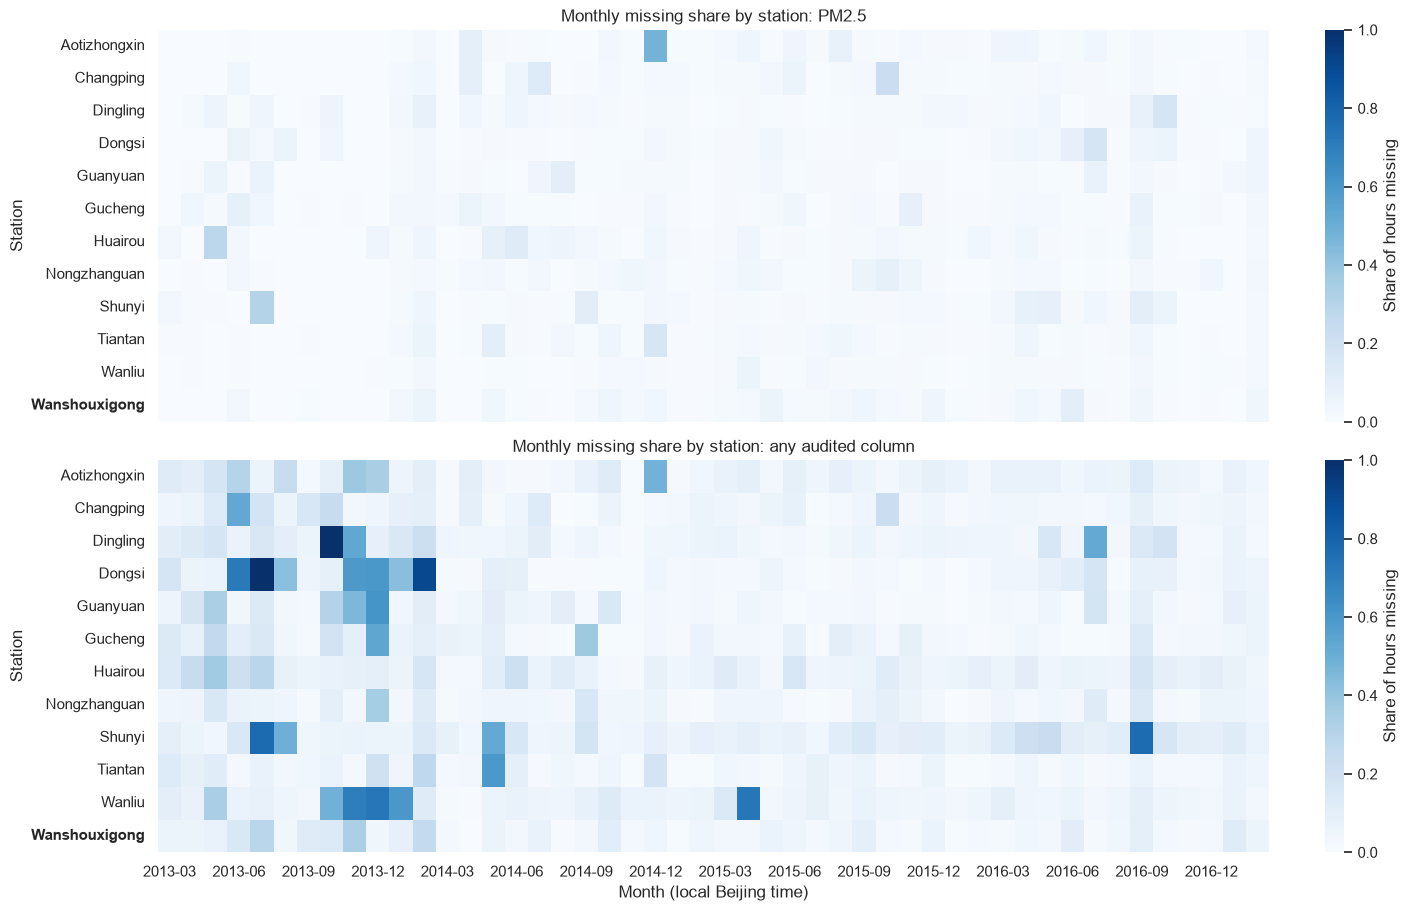

,mean_station_missing_share,stations_above_5pct,Wanshouxigong_missing_share
timestamp,,,
2014-12,0.076,2,0.038
2016-09,0.050,4,0.040
2014-02,0.042,3,0.057
2013-07,0.041,2,0.003
2015-10,0.037,2,0.020
2013-05,0.036,3,0.001


Mean monthly share of rows missing any audited column, 2013-03 to 2014-02: 0.185
Mean monthly share of rows missing any audited column, 2014-03 to 2017-02: 0.061
Ratio: 3.1


In [6]:
month = stations["timestamp"].dt.to_period("M")
missing_indicators = pd.DataFrame(
    {
        "PM2.5": stations["PM2.5"].isna(),
        "any audited column": stations[AUDIT_COLUMNS].isna().any(axis=1),
    }
)
monthly_missing = missing_indicators.groupby([stations["station"], month]).mean()

# One colour scale for both panels so that equal shades mean equal missing shares.
color_max = monthly_missing.to_numpy().max()
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
for ax, column in zip(axes, monthly_missing.columns):
    grid = monthly_missing[column].unstack("timestamp")
    grid.columns = grid.columns.astype(str)
    sns.heatmap(
        grid,
        ax=ax,
        cmap="Blues",
        vmin=0,
        vmax=color_max,
        xticklabels=3,
        cbar_kws={"label": "Share of hours missing"},
    )
    ax.set_title(f"Monthly missing share by station: {column}")
    ax.set_xlabel("")
    ax.set_ylabel("Station")
    for label in ax.get_yticklabels():
        if label.get_text() == SELECTED_STATION:
            label.set_fontweight("bold")
axes[-1].set_xlabel("Month (local Beijing time)")
plt.show()

# Months in which the most stations lose PM2.5 values at the same time.
pm25_monthly = monthly_missing["PM2.5"].unstack("station")
monthly_peaks = pd.DataFrame(
    {
        "mean_station_missing_share": pm25_monthly.mean(axis=1),
        "stations_above_5pct": (pm25_monthly > 0.05).sum(axis=1),
        f"{SELECTED_STATION}_missing_share": pm25_monthly[SELECTED_STATION],
    }
).sort_values("mean_station_missing_share", ascending=False)
display(monthly_peaks.head(6).round(3))

# Compare the first 12 months with the rest of the record, averaged over stations and months.
any_monthly = monthly_missing["any audited column"].unstack("station").mean(axis=1)
first_year = any_monthly.index < pd.Period("2014-03", freq="M")
first_year_any_missing = float(any_monthly[first_year].mean())
later_any_missing = float(any_monthly[~first_year].mean())
first_year_ratio = first_year_any_missing / later_any_missing
peak_month = monthly_peaks.index[0]
peak_month_station = pm25_monthly.loc[peak_month].idxmax()
peak_month_stations_above_5pct = int(monthly_peaks.iloc[0]["stations_above_5pct"])
print(f"Mean monthly share of rows missing any audited column, 2013-03 to 2014-02: {first_year_any_missing:.3f}")
print(f"Mean monthly share of rows missing any audited column, 2014-03 to 2017-02: {later_any_missing:.3f}")
print(f"Ratio: {first_year_ratio:.1f}")


In [7]:
pm25_missing = stations.pivot(index="timestamp", columns="station", values="PM2.5").isna()
selected_missing = pm25_missing[SELECTED_STATION]
other_missing = pm25_missing.drop(columns=SELECTED_STATION)

selected_missing_hours = int(selected_missing.sum())
shared_with_any_other = float(other_missing[selected_missing].any(axis=1).mean())
shared_with_all_others = float(other_missing[selected_missing].all(axis=1).mean())
# Expected share if every station lost values independently of the others at its own rate.
shared_if_independent = float(1 - (1 - other_missing.mean()).prod())
citywide_missing_hours = int(pm25_missing.all(axis=1).sum())

stations_missing_per_hour = pm25_missing.sum(axis=1)
missing_station_counts = (
    stations_missing_per_hour[stations_missing_per_hour > 0]
    .value_counts()
    .sort_index()
    .rename_axis("stations missing PM2.5")
    .rename("hours")
)

print(f"{SELECTED_STATION} hours without PM2.5: {selected_missing_hours}")
print(f"Share also missing at one or more other stations: {shared_with_any_other:.3f}")
print(f"Share expected under independence across stations: {shared_if_independent:.3f}")
print(f"Share missing at all 11 other stations: {shared_with_all_others:.3f}")
print(f"Hours without PM2.5 at all 12 stations: {citywide_missing_hours}")
display(missing_station_counts.to_frame().T)

# Long gaps in several pollutant columns that begin at the same hour.
gap_start_columns = selected_long_gaps.groupby("gap_start")["variable"].agg(["nunique", ", ".join])
shared_gap_starts = gap_start_columns.loc[gap_start_columns["nunique"] >= 3].rename(
    columns={"nunique": "columns", "join": "variables"}
)
print(f"{SELECTED_STATION} long-gap start hours shared by three or more columns:")
display(shared_gap_starts)


Wanshouxigong hours without PM2.5: 696
Share also missing at one or more other stations: 0.481
Share expected under independence across stations: 0.207
Share missing at all 11 other stations: 0.116
Hours without PM2.5 at all 12 stations: 81


stations missing PM2.5,1,2,3,4,5,6,8,11,12
hours,5227,906,120,40,8,7,2,10,81


Wanshouxigong long-gap start hours shared by three or more columns:


,columns,variables
gap_start,,
2014-02-16 16:00:00,4,"CO, NO2, O3, SO2"
2014-05-06 11:00:00,4,"CO, NO2, O3, SO2"
2014-10-24 09:00:00,5,"CO, NO2, PM10, PM2.5, SO2"
2016-06-25 17:00:00,6,"CO, NO2, O3, PM10, PM2.5, SO2"


All {eval}`len(timestamp_audit)` stations have {eval}`station_rows` hourly records from {eval}`record_start` to {eval}`record_end` in time order, with no duplicate or absent timestamps (`timestamp_audit`), so they differ only in missing values. No weather column or `wd` has a gap longer than {eval}`weather_longest_gap_hours` hours at any station, which is shorter than every station's longest pollutant gap, so the pollutant columns decide the choice.

The rule selects {eval}`SELECTED_STATION` (`SELECTED_STATION`). Its worst gap is a single {eval}`selected_worst_gap_hours`-hour outage beginning {eval}`selected_worst_gap_start` that removes {eval}`selected_worst_gap_variables` together. The runner-up, {eval}`runner_up_station`, has a worst gap of {eval}`runner_up_worst_gap_hours` hours in {eval}`runner_up_worst_gap_variable`, and {eval}`stations_with_worst_gap_over_300` stations have a worst gap above 300 hours. On the targets alone the selected station is good but not the best: its {eval}`selected_pm25_gap_hours`-hour PM2.5 gap ranks {eval}`selected_pm25_gap_rank` of 12, behind {eval}`pm25_shorter_gap_stations`, and its PM2.5 missing rate ranks {eval}`selected_pm25_missing_rank` of 12. Its pollutant covariates rank between {eval}`covariate_rank_best` and {eval}`covariate_rank_worst` on each measure (`selected_station_ranks`, where 1 is best). The rule was written after viewing the audit tables.

The choice depends on the rule, since {eval}`alternatives_choosing_other` of the {eval}`len(rule_comparison)` alternatives select another station (`rule_comparison`). Applying the primary rule to the two targets alone selects {eval}`target_rule_station`, whose longest target gap is {eval}`target_rule_target_gap_hours` hours but whose longest {eval}`target_rule_worst_covariate` gap is {eval}`target_rule_worst_covariate_gap` hours. The mean-rank and summed long-gap-hours rules select {eval}`aggregate_rule_station`, which has {eval}`f"{aggregate_rule_long_gap_hours:,}"` missing hours in long gaps summed over the audited columns, against {eval}`f"{selected_long_gap_hours_total:,}"` for the selected station, but a longer worst gap of {eval}`aggregate_rule_worst_gap_hours` hours. The selected station ranks {eval}`worst_alternative_rank` or better under every rule. Between it and {eval}`aggregate_rule_station`, the decision rests on preferring the shortest worst-case interpolation span, because a single long reconstructed stretch has the largest effect on decomposition, autocorrelation, and lag features.

Across the network, missing values cluster in time: rows missing at least one audited column are {eval}`f"{first_year_ratio:.1f}"` times as common in the first 12 months as in the rest of the record ({eval}`f"{first_year_any_missing:.1%}"` against {eval}`f"{later_any_missing:.1%}"` of rows, `first_year_any_missing` and `later_any_missing`), and most of the darkest cells in the lower heatmap fall in that first year. The PM2.5 peaks come from a few stations rather than the whole network; in the worst month, {eval}`f"{peak_month}"`, {eval}`peak_month_stations_above_5pct` stations exceed a 5% missing share, led by {eval}`peak_month_station` (`monthly_peaks`). Gaps also coincide across stations: of the selected station's {eval}`selected_missing_hours` hours without PM2.5, {eval}`f"{shared_with_any_other:.0%}"` are also missing at one or more other stations, against {eval}`f"{shared_if_independent:.0%}"` expected if each station lost values independently at its own rate, and all 12 stations lack PM2.5 in {eval}`citywide_missing_hours` hours. Within the selected station, {eval}`len(shared_gap_starts)` long-gap start hours are shared by three or more pollutant columns (`shared_gap_starts`). This pattern points to outages of a whole station or of the network rather than of single readings, although the dataset does not record causes.

The clustering matters for the preprocessing chapter in two ways. Native gaps are not scattered uniformly in time, so a mask of uniformly random hours tests the reconstruction of isolated hours, not of the {eval}`selected_shortest_long_gap_hours`- to {eval}`selected_worst_gap_hours`-hour outages in this station's record. And because gaps are more frequent early in the record across the network, they fall in any chronological training interval; the split audit below shows that the selected station follows this pattern in some columns but not in its targets. Clustering in time does not reveal whether missingness depends on the unobserved pollutant values themselves, which the observed data cannot test.

The conclusions that follow therefore describe one station chosen for short gaps. Stations with long covariate gaps, such as {eval}`worst_station` with a {eval}`worst_station_gap_hours`-hour {eval}`worst_station_gap_variable` gap, would need a different gap policy before the same multivariate analysis applies, and because this section compares missingness only, it does not show that the selected station's pollutant levels are typical of the city.

## Audit timestamps and define splits

Timestamp errors can turn a repeated record into apparent persistence or make a two-hour separation look like one hour, so the audit keeps file order until ordering, duplicates, and missing grid hours have been checked. The source's year, month, day, and hour fields are local Beijing civil time (UTC+8, with no daylight-saving changes in this record), and they stay timezone-naive throughout the book rather than being treated as UTC.

The selected station keeps its entire hourly record. Training is the half-open interval [2013-03-01, 2015-03-01), validation is [2015-03-01, 2016-03-01), and testing is [2016-03-01, 2017-03-01). Two training years allow repeated annual patterns to be compared, and each holdout contains one full seasonal cycle. All variables and both targets use these boundaries. No values are imputed or dropped here; holdout summaries report availability only, and the rest of the EDA uses training values exclusively.


In [8]:
from preprocessing.air_quality import chronological_split

VALIDATION_START = pd.Timestamp("2015-03-01")
TEST_START = pd.Timestamp("2016-03-01")
TIMEZONE_POLICY = "Naive local Beijing civil time, UTC+8; no DST in the study interval"

selected_file_rows = stations.loc[stations["station"].eq(SELECTED_STATION)].copy()
selected_timestamps = selected_file_rows["timestamp"]
assert selected_timestamps.is_monotonic_increasing
assert selected_timestamps.is_unique
hourly_grid = pd.date_range(selected_timestamps.min(), selected_timestamps.max(), freq="h")
assert pd.DatetimeIndex(selected_timestamps).equals(hourly_grid)

selected = selected_file_rows.set_index("timestamp").reindex(hourly_grid)
selected.index.name = "timestamp"
frequency = pd.infer_freq(selected.index)
meets_duration_requirement = selected.index[-1] + pd.Timedelta(hours=1) >= selected.index[0] + pd.DateOffset(years=2)
assert frequency == "h" and meets_duration_requirement

train, validation, test = chronological_split(
    selected, validation_start=VALIDATION_START, test_start=TEST_START,
)
splits = {"train": train, "validation": validation, "test": test}
assert train.index.max() < validation.index.min() < test.index.min()
assert len(train) + len(validation) + len(test) == len(selected)
split_summary = pd.DataFrame(
    {
        name: {
            "start_inclusive": part.index[0],
            "end_exclusive": part.index[-1] + pd.Timedelta(hours=1),
            "grid_hours": len(part),
            "observed_PM2.5": int(part["PM2.5"].notna().sum()),
            "observed_PM10": int(part["PM10"].notna().sum()),
        }
        for name, part in splits.items()
    }
).T
missing_values_by_split = pd.DataFrame(
    {name: part[AUDIT_COLUMNS].isna().sum() for name, part in splits.items()}
)
missing_share_by_split = missing_values_by_split.div(
    pd.Series({name: len(part) for name, part in splits.items()}), axis="columns",
)
source_metadata = {
    "dataset": "Beijing Multi-Site Air Quality, UCI 501",
    "source_url": AIR_QUALITY_URL,
    "archive_sha256": AIR_QUALITY_SHA256,
    "station": SELECTED_STATION,
    "frequency": frequency,
    "timezone_policy": TIMEZONE_POLICY,
    "filtering": "One station; all its hours and original values retained",
    "meets_two_year_requirement": bool(meets_duration_requirement),
}
display(pd.Series(source_metadata, name="value").to_frame())
display(split_summary)
print("Native missing-value counts by variable and interval:")
display(missing_values_by_split)
print("Native missing shares, using all grid hours in each interval:")
display(missing_share_by_split.round(4))

# Shares quoted in the interpretation; the assertions guard the stated directions.
split_missing_pct = {
    (column, name): f"{missing_share_by_split.loc[column, name]:.2%}"
    for column in AUDIT_COLUMNS for name in splits
}
assert (missing_share_by_split.loc[TARGET_COLUMNS, "train"] < missing_share_by_split.loc[TARGET_COLUMNS, "validation"]).all()
assert (missing_share_by_split.loc[["CO", "O3"], "train"] > missing_share_by_split.loc[["CO", "O3"], "validation"]).all()


C:\Users\BBQ\AppData\Local\Temp\ipykernel_9076\877254923.py:16: Pandas4Warning: A future version of pandas will return a BaseOffset object instead of a string from infer_freq. Use pd.set_option('future.infer_freq_returns_offset', True) to get the future behavior, or set to False to keep the old behavior and silence this warning. To preserve the string representation, use ``infer_freq(...).freqstr``.
  frequency = pd.infer_freq(selected.index)


,value
dataset,"Beijing Multi-Site Air Quality, UCI 501"
source_url,https://archive.ics.uci.edu/static/public/501/...
archive_sha256,b04da438b2f331ac0ffd45aebdfec0d20d2367feb5f694...
station,Wanshouxigong
frequency,h
timezone_policy,"Naive local Beijing civil time, UTC+8; no DST ..."
filtering,One station; all its hours and original values...
meets_two_year_requirement,True


,start_inclusive,end_exclusive,grid_hours,observed_PM2.5,observed_PM10
train,2013-03-01 00:00:00,2015-03-01 00:00:00,17520,17263,17341
validation,2015-03-01 00:00:00,2016-03-01 00:00:00,8784,8557,8657
test,2016-03-01 00:00:00,2017-03-01 00:00:00,8760,8548,8582


Native missing-value counts by variable and interval:


,train,validation,test
PM2.5,257,227,212
PM10,179,127,178
SO2,384,112,173
NO2,437,138,179
CO,930,130,237
O3,792,109,177
TEMP,1,0,18
PRES,1,0,18
DEWP,1,0,18
RAIN,1,0,18


Native missing shares, using all grid hours in each interval:


,train,validation,test
PM2.5,0.0147,0.0258,0.0242
PM10,0.0102,0.0145,0.0203
SO2,0.0219,0.0128,0.0197
NO2,0.0249,0.0157,0.0204
CO,0.0531,0.0148,0.0271
O3,0.0452,0.0124,0.0202
TEMP,0.0001,0.0000,0.0021
PRES,0.0001,0.0000,0.0021
DEWP,0.0001,0.0000,0.0021
RAIN,0.0001,0.0000,0.0021


The selected record already forms an ordered, unique hourly grid, so no deduplication, reordering, or inserted hours are needed; the quality issue is missing measurements at existing hours. `split_summary` confirms the shared boundaries and observed target counts, and `missing_values_by_split` keeps the native gaps visible. The full record meets the assignment's duration and frequency requirements without aggregation or subsampling.

The network-wide excess of gaps in the first year does not carry over to this station's targets. PM2.5 is missing in {eval}`split_missing_pct[("PM2.5", "train")]` of training hours against {eval}`split_missing_pct[("PM2.5", "validation")]` of validation hours, and PM10 in {eval}`split_missing_pct[("PM10", "train")]` against {eval}`split_missing_pct[("PM10", "validation")]`. CO and O3 do follow the network pattern, with {eval}`split_missing_pct[("CO", "train")]` and {eval}`split_missing_pct[("O3", "train")]` missing in training against {eval}`split_missing_pct[("CO", "validation")]` and {eval}`split_missing_pct[("O3", "validation")]` in validation. Gap policies fitted on training data will therefore meet different gap rates in the holdouts, and such differences do not justify moving a split boundary after seeing model performance.

## Inspect trend and seasonality

The training plots show the original observations, with pollution episodes, changes in level, and gaps left as they are, and a monthly median overlay summarizes slower variation without fitting a trend. Calendar profiles then group the same observed hours by hour of day, day of week, and month; their medians and interquartile ranges describe recurring patterns, while the count tables show that coverage is unequal. These are descriptive summaries, not significance tests. With only two annual cycles, a winter–summer contrast can suggest annual seasonality but cannot establish a long-term trend or explain a particular episode, and daily and weekly structure also needs the lag diagnostics below.


,count,mean,std,min,25%,50%,75%,max
PM2.5,17263.0,88.12,81.81,3.0,25.0,67.0,125.0,704.0
PM10,17341.0,120.20,98.59,2.0,45.0,101.0,167.0,961.0


,PM2.5,PM10
timestamp,,
2013-03-01,86.0,109.0
2013-04-01,69.0,88.0
2013-05-01,71.0,122.0
2013-06-01,97.0,116.0
2013-07-01,53.0,58.0
2013-08-01,47.0,68.0
2013-09-01,51.0,105.0
2013-10-01,67.0,111.5
2013-11-01,53.0,88.0


,PM2.5,PM10
timestamp,,
2013-03-01,744,744
2013-04-01,718,719
2013-05-01,743,744
2013-06-01,696,718
2013-07-01,742,741
2013-08-01,742,742
2013-09-01,713,720
2013-10-01,743,744
2013-11-01,719,719


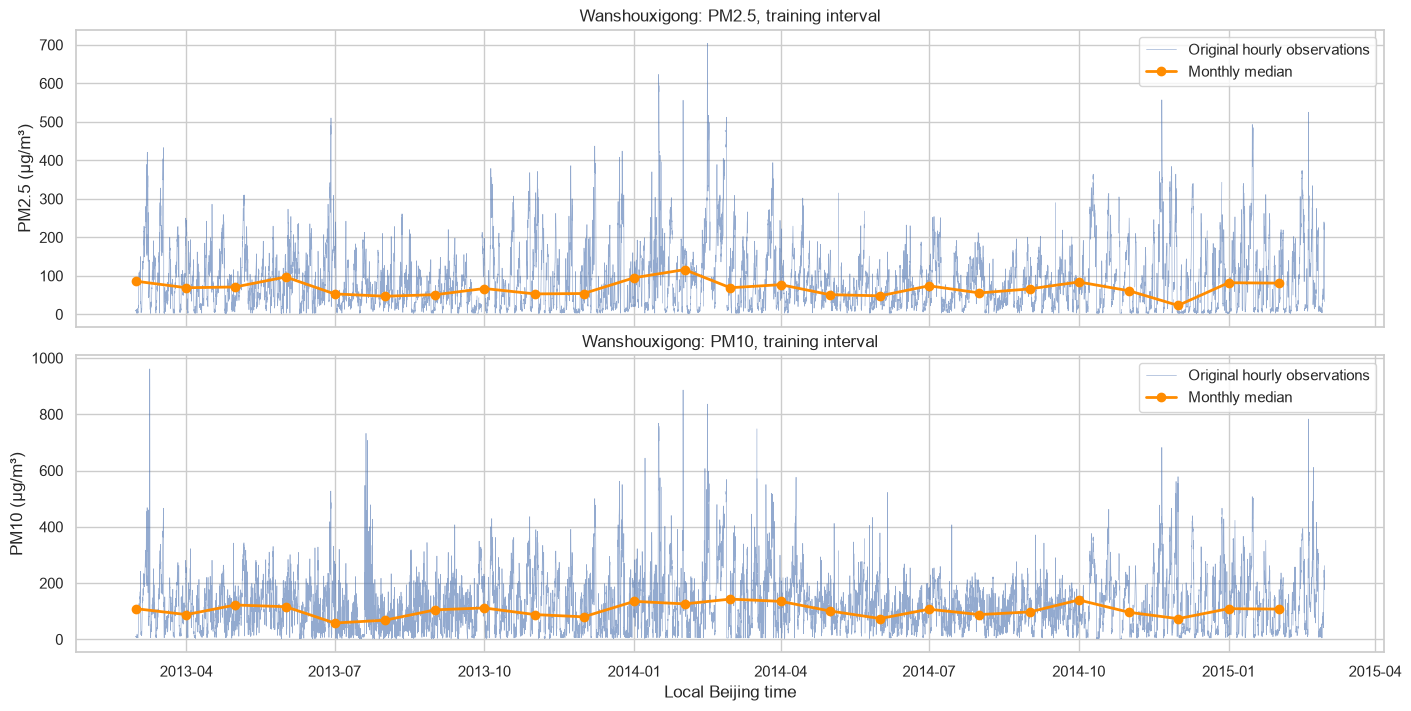

C:\Users\BBQ\AppData\Local\Temp\ipykernel_9076\2612873353.py:17: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  calendar_keys = {"hour": train.index.hour, "weekday": train.index.dayofweek, "month": train.index.month}


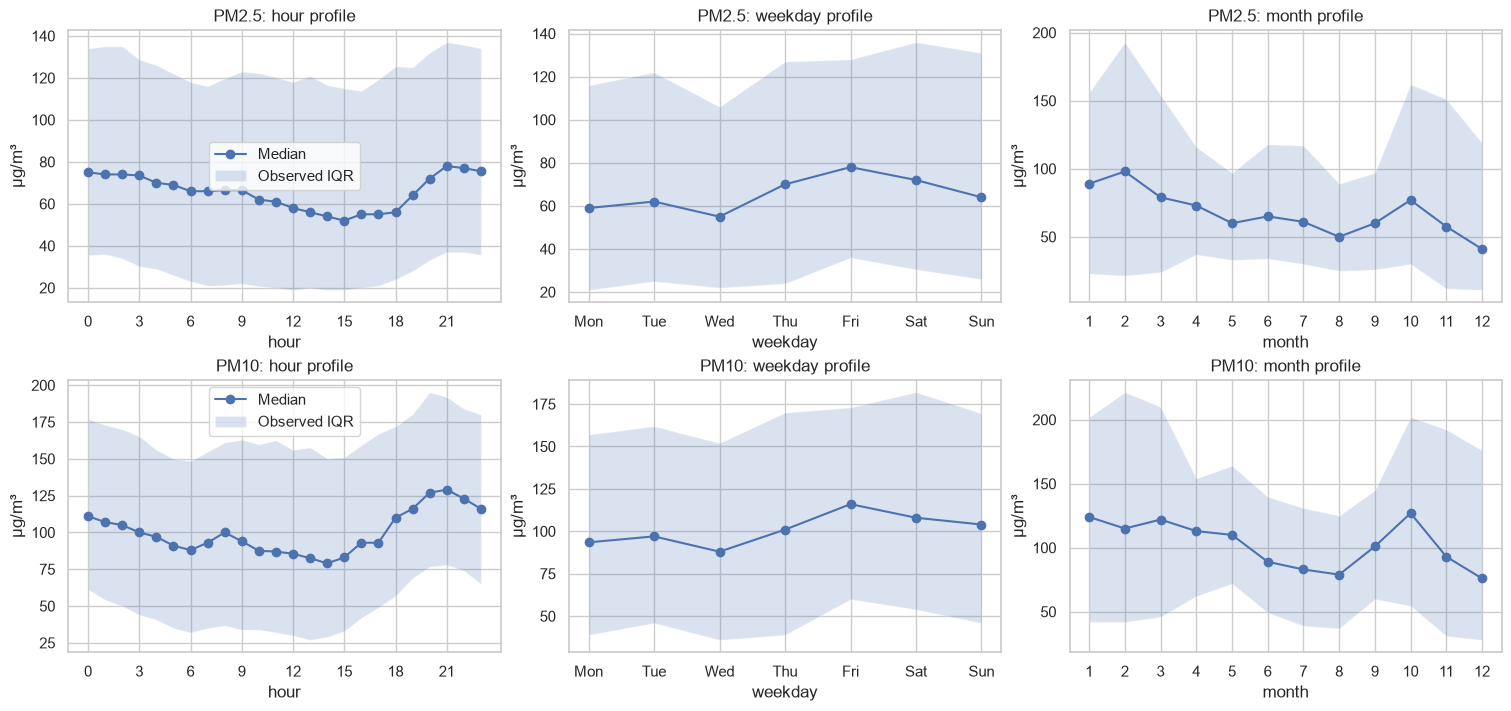

count  median    q25     q75
target period position                              
PM2.5  hour   0           719    75.0  35.50  134.00
              1           720    74.0  36.00  135.00
              2           720    74.0  34.00  135.00
              3           718    73.5  30.25  128.75
              4           720    70.0  29.00  126.00
...                       ...     ...    ...     ...
PM10   month  8          1485    79.0  37.00  125.00
              9          1440   101.0  60.00  145.00
              10         1455   127.0  54.50  202.00
              11         1424    93.0  31.00  192.25
              12         1465    76.0  28.00  176.00

[86 rows x 4 columns]

,year_1_median,year_2_median,pooled_iqr,median_abs_hourly_change,hourly_change_pairs
PM2.5,69.0,64.0,100.0,6.0,17192.0
PM10,99.0,103.0,122.0,13.0,17294.0


median_range  range_to_pooled_iqr  median_within_group_iqr  \
target period                                                                
PM2.5  hour             26.0                0.260                    98.50   
       weekday          23.0                0.230                    97.00   
       month            57.0                0.570                    97.50   
PM10   hour             50.0                0.410                   118.25   
       weekday          28.0                0.230                   118.00   
       month            51.0                0.418                   119.75   

                between_year_profile_correlation  
target period                                     
PM2.5  hour                                0.792  
       weekday                             0.485  
       month                               0.340  
PM10   hour                                0.947  
       weekday                             0.498  
       month                               0.188

In [9]:
training_target_summary = train[TARGET_COLUMNS].describe().T
monthly_medians = train[TARGET_COLUMNS].resample("MS").median()
monthly_observed_counts = train[TARGET_COLUMNS].resample("MS").count()
display(training_target_summary.round(2))
display(monthly_medians.round(2))
display(monthly_observed_counts)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    ax.plot(train.index, train[target], lw=0.45, alpha=0.6, label="Original hourly observations")
    ax.plot(monthly_medians.index, monthly_medians[target], "o-", color="darkorange", lw=2, label="Monthly median")
    ax.set(title=f"{SELECTED_STATION}: {target}, training interval", ylabel=f"{target} (µg/m³)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Local Beijing time")
plt.show()

calendar_keys = {"hour": train.index.hour, "weekday": train.index.dayofweek, "month": train.index.month}
calendar_profiles = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for row, target in enumerate(TARGET_COLUMNS):
    for col, (period, key) in enumerate(calendar_keys.items()):
        grouped = train[target].groupby(key)
        profile = grouped.agg(count="count", median="median")
        profile["q25"] = grouped.quantile(0.25)
        profile["q75"] = grouped.quantile(0.75)
        calendar_profiles[(target, period)] = profile
        ax = axes[row, col]
        ax.plot(profile.index, profile["median"], "o-", label="Median")
        ax.fill_between(profile.index, profile["q25"], profile["q75"], alpha=0.2, label="Observed IQR")
        ax.set(title=f"{target}: {period} profile", xlabel=period, ylabel="µg/m³")
        if period == "weekday":
            ax.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
        if period == "month":
            ax.set_xticks(range(1, 13))
        if period == "hour":
            ax.set_xticks(range(0, 24, 3))
        if col == 0:
            ax.legend()
plt.show()
calendar_profile_table = pd.concat(calendar_profiles, names=["target", "period", "position"])
display(calendar_profile_table.round(2))

# Each training year runs March to February, so both contain one full annual cycle.
SECOND_YEAR_START = VALIDATION_START - pd.DateOffset(years=1)
training_year = pd.Series(
    np.where(train.index < SECOND_YEAR_START, "year_1", "year_2"), index=train.index, name="training_year"
)
component_summary = pd.DataFrame(
    {
        target: {
            "year_1_median": train[target].loc[training_year.eq("year_1")].median(),
            "year_2_median": train[target].loc[training_year.eq("year_2")].median(),
            "pooled_iqr": train[target].quantile(0.75) - train[target].quantile(0.25),
            # diff() on the hourly grid is NaN unless both adjacent hours are observed.
            "median_abs_hourly_change": train[target].diff().abs().median(),
            "hourly_change_pairs": int(train[target].diff().notna().sum()),
        }
        for target in TARGET_COLUMNS
    }
).T
calendar_effect_rows = []
for target in TARGET_COLUMNS:
    for period, key in calendar_keys.items():
        profile = calendar_profiles[(target, period)]
        by_year = train[target].groupby([training_year, key]).median().unstack("training_year")
        calendar_effect_rows.append(
            {
                "target": target, "period": period,
                "median_range": profile["median"].max() - profile["median"].min(),
                "range_to_pooled_iqr": (profile["median"].max() - profile["median"].min())
                / component_summary.loc[target, "pooled_iqr"],
                "median_within_group_iqr": (profile["q75"] - profile["q25"]).median(),
                "between_year_profile_correlation": by_year["year_1"].corr(by_year["year_2"]),
            }
        )
calendar_effect_summary = pd.DataFrame(calendar_effect_rows).set_index(["target", "period"])
display(component_summary.round(2))
display(calendar_effect_summary.round(3))


The time plots are read for trend, seasonality, and noise, as visual identifications backed by descriptive summaries.

Neither target shows a smooth monotonic trend; the hourly plots alternate between sharp pollution episodes and quieter stretches. The PM2.5 median is {eval}`f"{component_summary.loc['PM2.5', 'year_1_median']:.0f}"` µg/m³ in the first training year and {eval}`f"{component_summary.loc['PM2.5', 'year_2_median']:.0f}"` µg/m³ in the second, and for PM10 it is {eval}`f"{component_summary.loc['PM10', 'year_1_median']:.0f}"` and {eval}`f"{component_summary.loc['PM10', 'year_2_median']:.0f}"` µg/m³ (`component_summary`), so the level moves between episodes without drifting steadily in one direction.

The hour-of-day profile is the clearest recurring pattern. Its medians span {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'hour'), 'median_range']:.0f}"` µg/m³ for PM2.5 and {eval}`f"{calendar_effect_summary.loc[('PM10', 'hour'), 'median_range']:.0f}"` µg/m³ for PM10, and the hourly profiles of the two training years correlate at {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'hour'), 'between_year_profile_correlation']:.2f}"` and {eval}`f"{calendar_effect_summary.loc[('PM10', 'hour'), 'between_year_profile_correlation']:.2f}"` (`calendar_effect_summary`). The weekday medians span {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'weekday'), 'median_range']:.0f}"` and {eval}`f"{calendar_effect_summary.loc[('PM10', 'weekday'), 'median_range']:.0f}"` µg/m³, close to the hourly range for PM2.5, but the weekday profiles correlate at only {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'weekday'), 'between_year_profile_correlation']:.2f}"` and {eval}`f"{calendar_effect_summary.loc[('PM10', 'weekday'), 'between_year_profile_correlation']:.2f}"` between years, so the weekday ordering does not repeat in this sample. Month-of-year medians span the widest range, {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'month'), 'median_range']:.0f}"` and {eval}`f"{calendar_effect_summary.loc[('PM10', 'month'), 'median_range']:.0f}"` µg/m³, yet the two years' monthly profiles correlate at only {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'month'), 'between_year_profile_correlation']:.2f}"` and {eval}`f"{calendar_effect_summary.loc[('PM10', 'month'), 'between_year_profile_correlation']:.2f}"`. Each month is observed once per year, so the winter–summer contrast suggests annual seasonality, but the two years do not share a stable monthly shape.

Hour-to-hour noise is low compared with the episodes. The median absolute change between consecutive observed hours is {eval}`f"{component_summary.loc['PM2.5', 'median_abs_hourly_change']:.0f}"` µg/m³ for PM2.5 and {eval}`f"{component_summary.loc['PM10', 'median_abs_hourly_change']:.0f}"` µg/m³ for PM10, small against pooled IQRs of {eval}`f"{component_summary.loc['PM2.5', 'pooled_iqr']:.0f}"` and {eval}`f"{component_summary.loc['PM10', 'pooled_iqr']:.0f}"` µg/m³, so multi-day episodes carry most of the variation. Within an hour-of-day group the median PM2.5 IQR is {eval}`f"{calendar_effect_summary.loc[('PM2.5', 'hour'), 'median_within_group_iqr']:.0f}"` µg/m³, close to the pooled IQR, so calendar position explains little of that episode-scale variation.

Both targets are right-skewed, with the mean above the median and a long upper tail (`training_target_summary`). Because the calendar profiles pool serially dependent hours and native gaps are clustered, neither their IQRs nor the between-year correlations are significance tests. The lag diagnostics below check whether 24- or 168-hour separations carry structure beyond slow persistence, and the preprocessing chapter assesses seasonality and stationarity before fitting a decomposition.

## Describe relationships among variables

Same-hour correlations summarize association and flag potentially redundant forecast features. Pearson's coefficient measures linear association and Spearman's measures association between ranks, and both use the training rows where the two values are observed. This pairwise deletion keeps more data than dropping every row with any gap, but different coefficients can then rest on different subsets, so `correlation_pair_counts` reports their denominators; missingness can still bias either measure. Pairs whose absolute coefficient exceeds 0.8 in either matrix are listed as candidates for redundancy.

Wind direction is converted from its 16 compass labels to angles clockwise from north. With wind speed $s$ in m/s and $\theta$ the direction the wind blows from, the components are $u=-s\sin\theta$ and $v=-s\cos\theta$. Calm air has no direction, so a zero speed gives $u=v=0$ even without a recorded direction; otherwise a missing direction or speed leaves both components missing, and nothing is inferred or filled. `wind_components` in `src/preprocessing/air_quality.py` implements the conversion for both chapters. WSPM stays in this section to show how it relates to the components, but the Granger design uses only $u$ and $v$, so that the two encodings are not treated as independent information.

These matrices describe simultaneous association, not independent effects or causation; lagged associations and shared weather drivers need separate analysis.


,missing_training_hours
u,2
v,2


Calm training hours without a recorded direction, set to u = v = 0: 1
Training RAIN: 96.684% zero among 17519 observed hours


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,u,v
PM2.5,17263,17257,17062,17008,16518,16623,17262,17262,17262,17262,17262,17261,17261
PM10,17257,17341,17118,17064,16572,16680,17340,17340,17340,17340,17340,17339,17339
SO2,17062,17118,17136,17023,16534,16642,17135,17135,17135,17135,17135,17134,17134
NO2,17008,17064,17023,17083,16482,16589,17082,17082,17082,17082,17082,17081,17081
CO,16518,16572,16534,16482,16590,16226,16589,16589,16589,16589,16589,16588,16588
O3,16623,16680,16642,16589,16226,16728,16727,16727,16727,16727,16727,16726,16726
TEMP,17262,17340,17135,17082,16589,16727,17519,17519,17519,17519,17519,17518,17518
PRES,17262,17340,17135,17082,16589,16727,17519,17519,17519,17519,17519,17518,17518
DEWP,17262,17340,17135,17082,16589,16727,17519,17519,17519,17519,17519,17518,17518
RAIN,17262,17340,17135,17082,16589,16727,17519,17519,17519,17519,17519,17518,17518


Pairs exceeding |r| = 0.8 in either descriptive matrix:


,first,second,pearson,spearman,observed_pairs,absolute_method_difference
0,PM2.5,PM10,0.857,0.845,17257,0.012
3,PM2.5,CO,0.790,0.847,16518,0.056
57,TEMP,PRES,-0.821,-0.829,17519,0.007
58,TEMP,DEWP,0.822,0.820,17519,0.002


Largest differences between linear and rank associations:


,first,second,pearson,spearman,observed_pairs,absolute_method_difference
76,WSPM,v,-0.300,-0.126,17518,0.174
45,CO,DEWP,-0.048,0.114,16589,0.162
75,WSPM,u,0.417,0.256,17518,0.161
77,u,v,-0.003,0.154,17518,0.157
34,NO2,O3,-0.507,-0.645,16589,0.139
54,O3,WSPM,0.244,0.382,16727,0.138
42,CO,O3,-0.320,-0.453,16226,0.132
7,PM2.5,DEWP,0.106,0.223,17262,0.117


Largest Pearson-Spearman difference in a pair with RAIN: 0.095


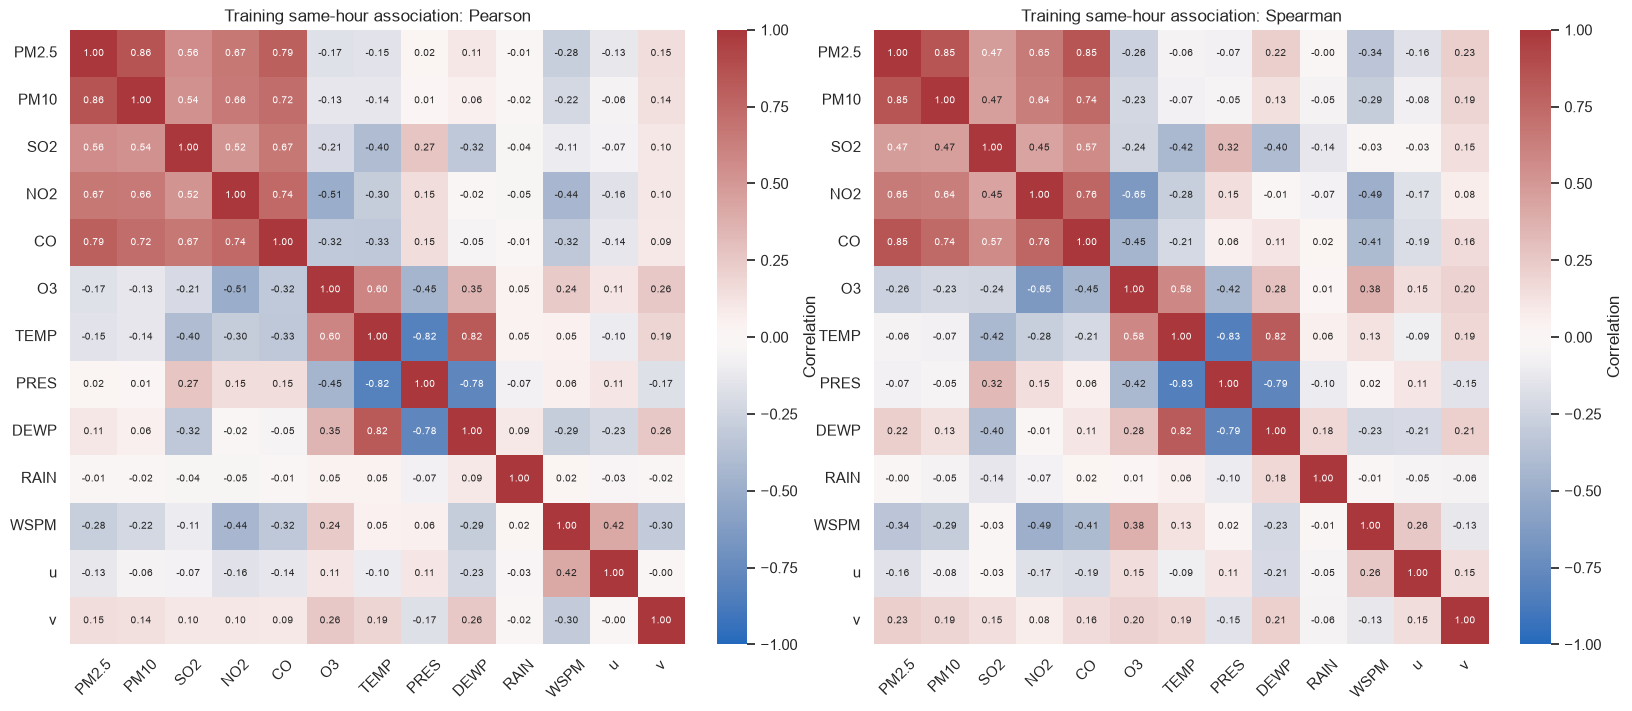

In [10]:
from preprocessing.air_quality import wind_components

STRONG_CORRELATION = 0.8
training_numeric = train[ANALYSIS_COLUMNS].join(wind_components(train["wd"], train["WSPM"]))
wind_missing_count = training_numeric[["u", "v"]].isna().sum()
calm_hours_without_direction = int((train["wd"].isna() & train["WSPM"].eq(0)).sum())
training_rain_observed_count = int(train["RAIN"].notna().sum())
training_rain_zero_share = float(train["RAIN"].dropna().eq(0).mean())

observed_numeric = training_numeric.notna().astype("int64")
correlation_pair_counts = observed_numeric.T @ observed_numeric
pearson_correlations = training_numeric.corr(method="pearson")
spearman_correlations = training_numeric.corr(method="spearman")
pair_rows, pair_cols = np.triu_indices(len(training_numeric.columns), k=1)
correlation_comparison = pd.DataFrame(
    [
        {
            "first": training_numeric.columns[i], "second": training_numeric.columns[j],
            "pearson": pearson_correlations.iloc[i, j],
            "spearman": spearman_correlations.iloc[i, j],
            "observed_pairs": int(correlation_pair_counts.iloc[i, j]),
        }
        for i, j in zip(pair_rows, pair_cols)
    ]
)
correlation_comparison["absolute_method_difference"] = (
    correlation_comparison["pearson"] - correlation_comparison["spearman"]
).abs()
strong_correlations = correlation_comparison.loc[
    correlation_comparison[["pearson", "spearman"]].abs().max(axis=1) > STRONG_CORRELATION
]
pair_correlation = correlation_comparison.set_index(["first", "second"])
largest_method_differences = correlation_comparison.nlargest(8, "absolute_method_difference")
involves_wind = largest_method_differences[["first", "second"]].isin(["WSPM", "u", "v"]).any(axis=1)
wind_pairs_in_largest = int(involves_wind.sum())
other_largest_pairs = ", ".join(
    f"{row.first}/{row.second}" for row in largest_method_differences.loc[~involves_wind].itertuples()
)
# The interpretation says every other large difference involves a pollutant.
POLLUTANT_COLUMNS = TARGET_COLUMNS + POLLUTANT_COVARIATES
assert largest_method_differences.loc[~involves_wind, ["first", "second"]].isin(POLLUTANT_COLUMNS).any(axis=1).all()
involves_rain = correlation_comparison[["first", "second"]].eq("RAIN").any(axis=1)
rain_max_method_difference = float(correlation_comparison.loc[involves_rain, "absolute_method_difference"].max())
display(wind_missing_count.rename("missing_training_hours").to_frame())
print(f"Calm training hours without a recorded direction, set to u = v = 0: {calm_hours_without_direction}")
print(f"Training RAIN: {training_rain_zero_share:.3%} zero among {training_rain_observed_count} observed hours")
display(correlation_pair_counts)
print(f"Pairs exceeding |r| = {STRONG_CORRELATION} in either descriptive matrix:")
display(strong_correlations.round(3))
print("Largest differences between linear and rank associations:")
display(largest_method_differences.round(3))
print(f"Largest Pearson-Spearman difference in a pair with RAIN: {rain_max_method_difference:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, matrix, title in zip(axes, [pearson_correlations, spearman_correlations], ["Pearson", "Spearman"]):
    sns.heatmap(matrix, vmin=-1, vmax=1, center=0, cmap="vlag", ax=ax, square=True,
                annot=True, fmt=".2f", annot_kws={"fontsize": 7}, cbar_kws={"label": "Correlation"})
    ax.set_title(f"Training same-hour association: {title}")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.show()


PM2.5 and PM10 have a Pearson correlation of {eval}`f"{pair_correlation.loc[('PM2.5', 'PM10'), 'pearson']:.2f}"` and a Spearman correlation of {eval}`f"{pair_correlation.loc[('PM2.5', 'PM10'), 'spearman']:.2f}"` on {eval}`f"{int(pair_correlation.loc[('PM2.5', 'PM10'), 'observed_pairs']):,}"` paired training hours, as their overlapping size definitions lead one to expect. TEMP and DEWP also move together, with a Pearson correlation of {eval}`f"{pair_correlation.loc[('TEMP', 'DEWP'), 'pearson']:.2f}"`. `strong_correlations` lists every pair above {eval}`STRONG_CORRELATION` in either matrix, and the pair-count matrix shows how the observation sets vary.

Of the eight largest Pearson-Spearman differences, {eval}`wind_pairs_in_largest` involve WSPM, $u$, or $v$ (`largest_method_differences`); the components are nonlinear functions of speed and direction, so linear and rank coefficients summarize them differently. The other large differences, {eval}`other_largest_pairs`, involve right-skewed pollutant concentrations, whose long upper tails affect Pearson's coefficient more than ranks. Rainfall plays no part, with a largest difference of {eval}`f"{rain_max_method_difference:.3f}"` against any variable, and neither coefficient alone describes every relationship.

These results argue for checking feature redundancy on training data rather than dropping a variable because of a heatmap. The wind components are related to WSPM by construction, and {eval}`calm_hours_without_direction` calm training hours without a recorded direction receive $u=v=0$ (`calm_hours_without_direction`). Most observed training hours have no rain ({eval}`f"{training_rain_zero_share:.1%}"`, `training_rain_zero_share`), so the Granger analysis must justify including such a sparse signal and cannot read a small p-value as a causal weather effect.

## Examine gap-aware ACF and PACF

Deleting missing rows would compress elapsed time, so that observations two hours apart could become adjacent. The estimators therefore keep the hourly grid. Let $m_t$ indicate an observed value, $\bar{x}$ be the mean of the observed training values, and $n_k=\sum_{t=k}^{N-1}m_tm_{t-k}$ be the number of observed endpoint pairs at lag $k$. The estimator is

$$
\hat\gamma_k=\frac{1}{n_k}\sum_{t=k}^{N-1}m_tm_{t-k}(x_t-\bar{x})(x_{t-k}-\bar{x}),
\qquad \hat\rho_k=\frac{\hat\gamma_k}{\hat\gamma_0}.
$$

Missing endpoints contribute no product, while an observed pair counts even if an hour between them is missing. `gap_aware_acf` uses [statsmodels `acovf`](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.acovf.html) with `missing="conservative"` and `adjusted=True`, dividing each lag by its own `pair_counts`; this does not assume that missingness is MCAR. The PACF comes from [Levinson–Durbin recursion](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.levinson_durbin.html) on these autocovariances: at order $k$, solve $\Gamma_k\phi_k=(\hat\gamma_1,\ldots,\hat\gamma_k)^T$, where $(\Gamma_k)_{ij}=\hat\gamma_{|i-j|}$, and take the final coefficient $\phi_{k,k}$. Pairwise covariance estimates need not form a positive-definite sequence, so the helper raises an error if the recursion produces a non-positive innovation variance instead of silently repairing it.

The plotted bands are $\pm1.96/\sqrt{n_k}$, using each lag's pair count rather than the grid size. They are approximate pointwise 95% white-noise bands, not simultaneous confidence intervals or calibrated tests for dependent, possibly non-stationary data, and because the PACF uses all lower-order covariances, its band is a further approximation. The arrays are plotted directly because the built-in bands of [`plot_acf`](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html) do not implement this per-lag pair-count convention.

The PACF and the order search stop at a short-range limit $L=\lfloor\min(10\log_{10}n,n/5)\rfloor$, capped below half the observed sample count, where $n$ is the number of observed training values. The assignment offers this formula as an example, so the chapter treats it as a starting point to check against the data. It is a common rule of thumb: statsmodels [`pacf`](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.pacf.html) uses $\min(10\log_{10}n,\lfloor n/2\rfloor-1)$ lags by default, and its `acf` also starts from $10\log_{10}n$. The $n/5$ term binds only for series of 100 observations or fewer, and the half-sample cap is the largest order the PACF helper accepts, so for two years of hourly data $L$ comes from $10\log_{10}n$ (`short_max_lag`). Three considerations decide whether this limit suits the data:

- Coverage: $L$ exceeds 24, so the search includes the daily lag and the lags on both sides of it rather than leaving lag 24 at the edge.
- Cost: BIC, defined below, compares orders on the hours whose value and all $L$ lags are observed, so each extra lag removes more hours near native gaps from that common sample.
- Sensitivity: the selected order should not depend on where the search stops. `lag_ceiling_sensitivity` refits the order criteria with ceilings from 24 to 168 hours, and `pacf_beyond_ceiling` reports the largest PACF coefficient beyond $L$.

A separate ACF extends to 336 hours to examine one- and two-week separations without widening the order search.

Two order rules are reported. The band rule takes the largest lag in $1,\ldots,L$ whose absolute PACF exceeds its band, or $p=0$ if none does. With about 17,000 observed hours the band is near $\pm0.015$, so the rule reacts to coefficients too small to matter, and with $L$ pointwise 5% tests about $0.05L$ false crossings are expected under white noise, which pushes the last crossing toward $L$. The band rule is therefore kept as a diagnostic only.

The candidate order instead comes from the Bayesian information criterion (BIC), applied to the autoregressions whose last coefficients the PACF estimates. For each $p=0,\ldots,L$, `ar_information_criteria` fits $x_t=c+\sum_{j=1}^{p}\phi_jx_{t-j}+\varepsilon_t$ by least squares and computes

$$
\mathrm{BIC}(p)=n_c\log(\mathrm{RSS}_p/n_c)+(p+1)\log n_c,
$$

where $\mathrm{RSS}_p$ is the residual sum of squares and $n_c$ is the number of hours whose value and all $L$ lags are observed. Every order uses these same $n_c$ hours, so orders are compared on identical observations and no hour is filled. AIC replaces $\log n_c$ with 2 and so penalizes extra lags less. Both criteria measure in-sample fit, which is why notebook 02 still compares candidate lag spans on validation data.

Repeating the estimators after training-only linear interpolation isolates the effect of filling. `acf_max_abs_difference` and `pacf_max_abs_difference` store the largest changes over nonzero short lags, `weekly_acf_max_abs_difference` covers the longer ACF range, and the BIC order is recomputed on the filled series. This retrospective sensitivity fill is not the filling method that notebook 02 selects.


target,PM2.5,PM10
grid_hours,17520,17520
observed_n,17263,17341
missing_share,0.014669,0.010217
short_max_lag,42,42
min_pair_count_short,16965,17120
max_band_increase_vs_full_grid_pct,1.622557,1.161479
max_abs_acf_difference,0.01375,0.012184
max_abs_pacf_difference,0.054134,0.022109
p_gap,39,42
p_filled,39,42


pacf  band_half_width
target lag_hours                         
PM2.5  1          0.9635           0.0149
       2         -0.1877           0.0150
       3         -0.0069           0.0150
       24        -0.0232           0.0150
       42         0.0072           0.0150
PM10   1          0.9075           0.0149
       2          0.0547           0.0149
       3          0.0148           0.0149
       24         0.0108           0.0150
       42         0.0260           0.0150

acf  pair_counts  band_half_width
target lag_hours                                        
PM2.5  1          0.963492        17192         0.014948
       12         0.530404        17048         0.015011
       24         0.332254        16986         0.015039
       42         0.098116        16965         0.015048
       168       -0.007774        16839         0.015104
       336        0.028333        16679         0.015176
PM10   1          0.907493        17294         0.014904
       12         0.415032        17190         0.014949
       24         0.289966        17141         0.014971
       42         0.087707        17120         0.014980
       168        0.053218        16994         0.015035
       336        0.052682        16829         0.015109

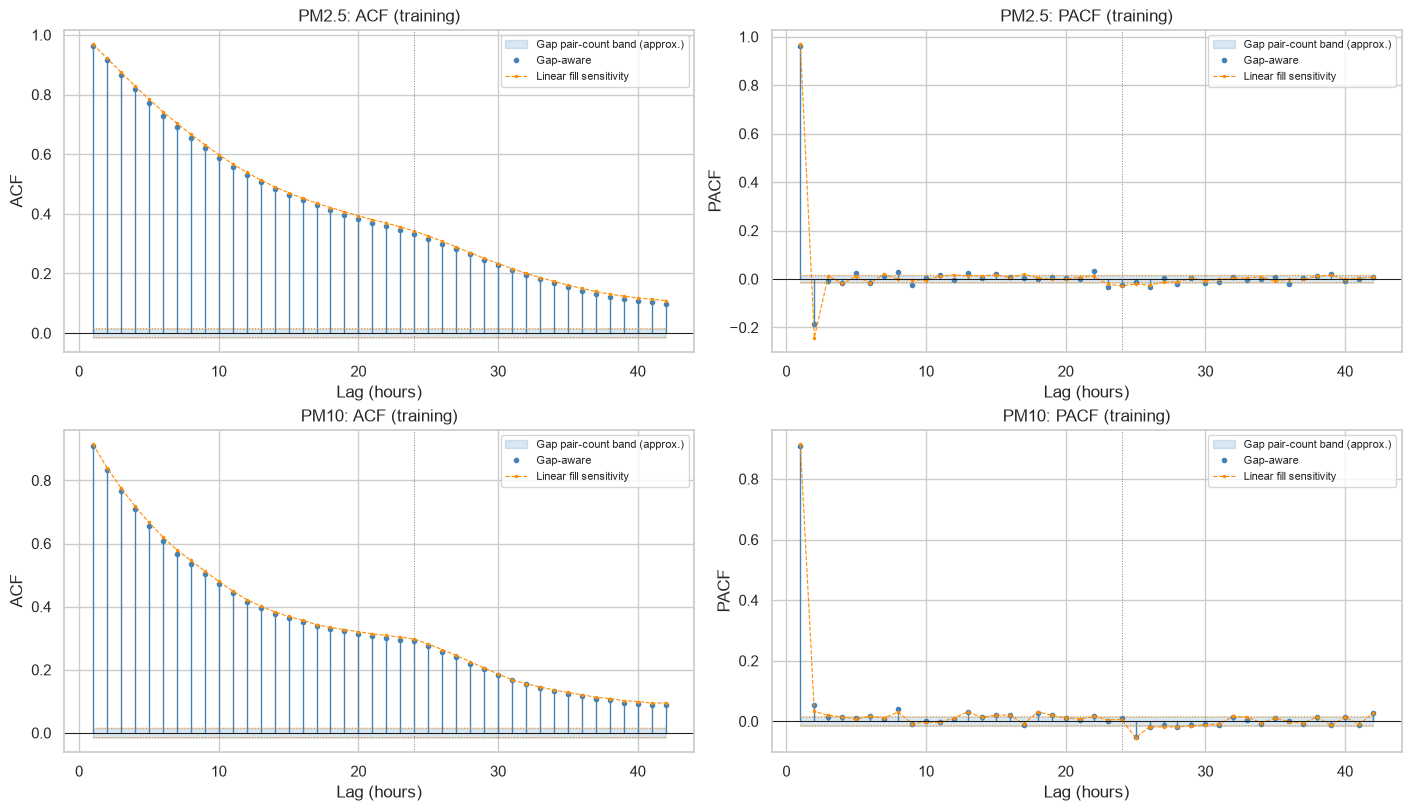

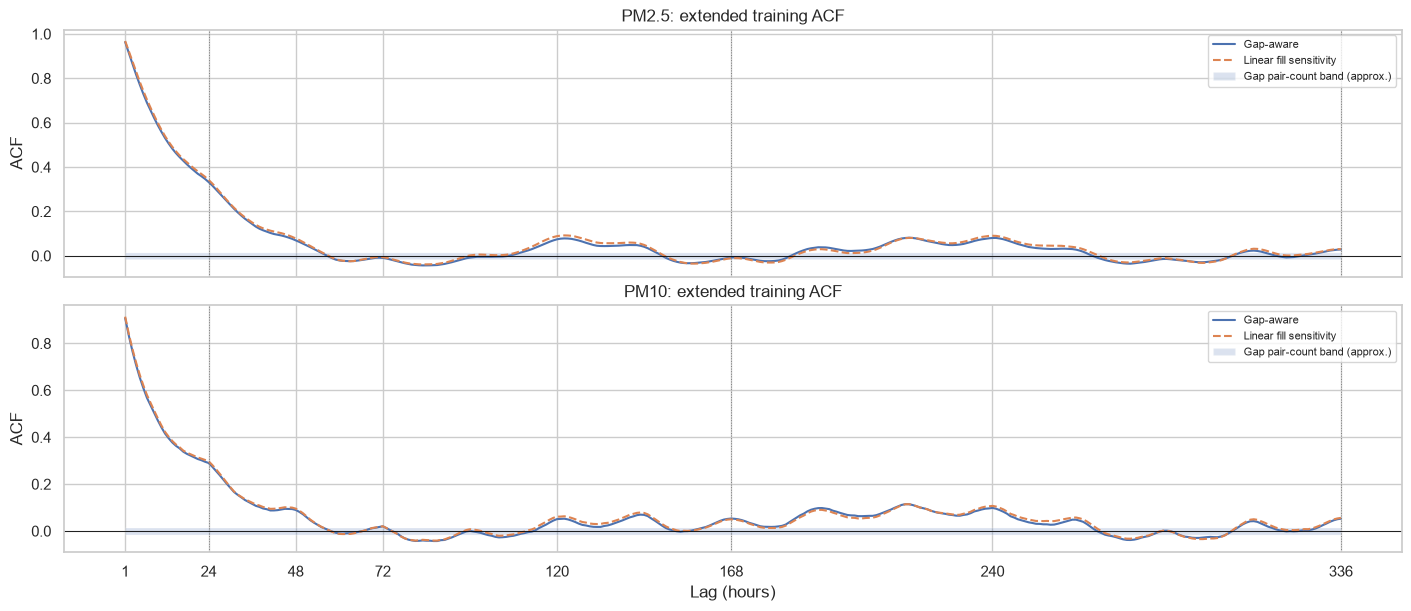

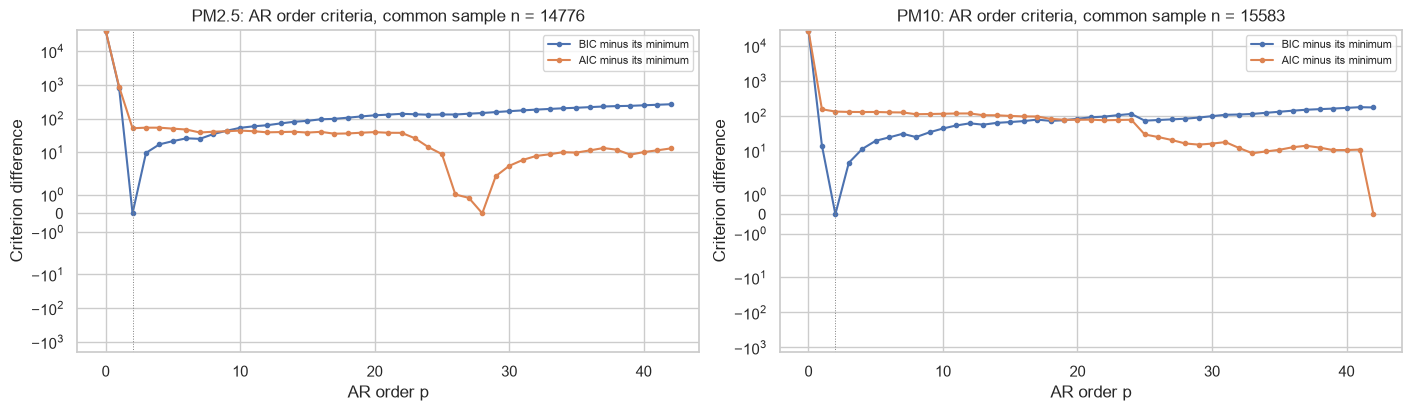

In [11]:
MAX_LAG_BY_TARGET = {
    target: int(min(10 * np.log10(train[target].notna().sum()), train[target].notna().sum() / 5,
                    train[target].notna().sum() // 2 - 1))
    for target in TARGET_COLUMNS
}
WEEKLY_MAX_LAG = 336
gap_dependence = {}
linear_dependence = {}
weekly_gap_acf = {}
weekly_linear_acf = {}
linear_sensitivity = {}
acf_max_abs_difference = {}
pacf_max_abs_difference = {}
weekly_acf_max_abs_difference = {}
pacf_selected_p = {}
linear_filled_selected_p = {}
information_criteria = {}
bic_selected_p = {}
aic_selected_p = {}
linear_filled_bic_p = {}
band_crossings = {}
max_abs_pacf_after_bic = {}
dependence_rows = []

for target in TARGET_COLUMNS:
    original = train[target]
    max_lag = MAX_LAG_BY_TARGET[target]
    filled = original.interpolate(method="time", limit_area="inside")
    assert filled.notna().all(), "Boundary gaps need a separate sensitivity policy"
    reference = gap_aware_pacf(original, max_lag)
    complete = gap_aware_pacf(filled, max_lag)
    gap_dependence[target] = reference
    linear_dependence[target] = complete
    weekly_gap_acf[target] = gap_aware_acf(original, WEEKLY_MAX_LAG)
    weekly_linear_acf[target] = gap_aware_acf(filled, WEEKLY_MAX_LAG)
    linear_sensitivity[target] = compare_filled_dependence(original, filled, max_lag)
    acf_max_abs_difference[target] = linear_sensitivity[target]["max_abs_acf_difference"]
    pacf_max_abs_difference[target] = linear_sensitivity[target]["max_abs_pacf_difference"]
    weekly_acf_max_abs_difference[target] = float(
        (weekly_gap_acf[target]["acf"] - weekly_linear_acf[target]["acf"]).abs().iloc[1:].max()
    )
    pacf_selected_p[target] = pacf_lag_order(reference)
    linear_filled_selected_p[target] = pacf_lag_order(complete)
    outside_gap = reference["pacf"].abs() > reference["band_half_width"]
    outside_linear = complete["pacf"].abs() > complete["band_half_width"]
    criteria = ar_information_criteria(original, max_lag)
    information_criteria[target] = criteria
    bic_selected_p[target] = int(criteria["bic"].idxmin())
    aic_selected_p[target] = int(criteria["aic"].idxmin())
    linear_filled_bic_p[target] = int(ar_information_criteria(filled, max_lag)["bic"].idxmin())
    band_crossings[target] = int(outside_gap.iloc[1:].sum())
    max_abs_pacf_after_bic[target] = float(
        reference["pacf"].loc[reference.index > bic_selected_p[target]].abs().max()
    )
    dependence_rows.append(
        {
            "target": target, "grid_hours": len(original), "observed_n": int(original.notna().sum()),
            "missing_share": float(original.isna().mean()), "short_max_lag": max_lag,
            "min_pair_count_short": int(reference["pair_counts"].iloc[1:].min()),
            "max_band_increase_vs_full_grid_pct": float(
                (reference["band_half_width"].iloc[1:] / (1.96 / np.sqrt(len(original))) - 1).max() * 100
            ),
            **linear_sensitivity[target],
            "changed_PACF_band_crossings": int((outside_gap != outside_linear).iloc[1:].sum()),
            "p_at_search_boundary": pacf_selected_p[target] == max_lag,
            "weekly_max_abs_acf_difference": weekly_acf_max_abs_difference[target],
            "band_crossings": band_crossings[target],
            "expected_false_crossings": 0.05 * max_lag,
            "max_abs_pacf_after_bic_p": max_abs_pacf_after_bic[target],
            "information_criterion_n": int(criteria["n_obs"].iloc[0]),
            "bic_p": bic_selected_p[target],
            "aic_p": aic_selected_p[target],
            "bic_p_linear_fill": linear_filled_bic_p[target],
        }
    )
dependence_summary = pd.DataFrame(dependence_rows).set_index("target")
display(dependence_summary.T)

pacf_reference_table = pd.concat(
    {target: gap_dependence[target].loc[[1, 2, 3, 24, MAX_LAG_BY_TARGET[target]], ["pacf", "band_half_width"]]
     for target in TARGET_COLUMNS}, names=["target", "lag_hours"],
)
display(pacf_reference_table.round(4))
daily_band_crossings = {
    target: [lag for lag in range(20, 29) if abs(gap_dependence[target].loc[lag, "pacf"])
             > gap_dependence[target].loc[lag, "band_half_width"]]
    for target in TARGET_COLUMNS
}
pm25_pacf_change_in_bands = pacf_max_abs_difference["PM2.5"] / gap_dependence["PM2.5"]["band_half_width"].iloc[1:].median()
lag_reference_table = pd.concat(
    {target: weekly_gap_acf[target].loc[[1, 12, 24, 42, 168, 336], ["acf", "pair_counts", "band_half_width"]]
     for target in TARGET_COLUMNS}, names=["target", "lag_hours"],
)
display(lag_reference_table.round(6))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for row, target in enumerate(TARGET_COLUMNS):
    reference = gap_dependence[target].iloc[1:]
    complete = linear_dependence[target].iloc[1:]
    for col, statistic in enumerate(["acf", "pacf"]):
        ax = axes[row, col]
        lags = reference.index.to_numpy()
        ax.fill_between(lags, -reference["band_half_width"], reference["band_half_width"],
                        color="steelblue", alpha=0.2, label="Gap pair-count band (approx.)")
        ax.vlines(lags, 0, reference[statistic], color="steelblue", lw=1)
        ax.plot(lags, reference[statistic], "o", color="steelblue", ms=3, label="Gap-aware")
        ax.plot(lags, complete[statistic], ".--", color="darkorange", ms=3, lw=0.8, label="Linear fill sensitivity")
        ax.plot(lags, complete["band_half_width"], ":", color="darkorange", lw=0.8)
        ax.plot(lags, -complete["band_half_width"], ":", color="darkorange", lw=0.8)
        ax.axhline(0, color="black", lw=0.6)
        ax.axvline(24, color="grey", lw=0.7, ls=":")
        ax.set(title=f"{target}: {statistic.upper()} (training)", xlabel="Lag (hours)", ylabel=statistic.upper())
        ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    reference = weekly_gap_acf[target].iloc[1:]
    ax.plot(reference.index, reference["acf"], label="Gap-aware")
    ax.plot(reference.index, weekly_linear_acf[target]["acf"].iloc[1:], "--", label="Linear fill sensitivity")
    ax.fill_between(reference.index, -reference["band_half_width"], reference["band_half_width"], alpha=0.2,
                    label="Gap pair-count band (approx.)")
    for lag in [24, 168, 336]:
        ax.axvline(lag, color="grey", lw=0.7, ls=":")
    ax.axhline(0, color="black", lw=0.6)
    ax.set(title=f"{target}: extended training ACF", ylabel="ACF")
    ax.legend(fontsize=8)
axes[-1].set(xlabel="Lag (hours)", xticks=[1, 24, 48, 72, 120, 168, 240, 336])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False, constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    criteria = information_criteria[target]
    for criterion in ["bic", "aic"]:
        ax.plot(criteria.index, criteria[criterion] - criteria[criterion].min(), "o-", ms=3,
                label=f"{criterion.upper()} minus its minimum")
    ax.axvline(bic_selected_p[target], color="grey", lw=0.7, ls=":")
    ax.set(title=f"{target}: AR order criteria, common sample n = {int(criteria['n_obs'].iloc[0])}",
           xlabel="AR order p", ylabel="Criterion difference", yscale="symlog")
    ax.legend(fontsize=8)
plt.show()


Both targets are strongly persistent from hour to hour, with a lag-1 ACF of {eval}`f"{weekly_gap_acf['PM2.5'].loc[1, 'acf']:.2f}"` for PM2.5 and {eval}`f"{weekly_gap_acf['PM10'].loc[1, 'acf']:.2f}"` for PM10. The extended ACF decays over the first day and is close to zero at one and two weeks (`lag_reference_table`), so the dependence is concentrated at the daily scale. A positive ACF at a seasonal lag would not by itself establish a seasonal peak; the neighbouring lags and the calendar profiles matter too.

The PACF looks like that of a low-order autoregression. The lag-1 partial autocorrelation equals the lag-1 ACF, and at lag 2 it is {eval}`f"{gap_dependence['PM2.5'].loc[2, 'pacf']:.3f}"` for PM2.5 and {eval}`f"{gap_dependence['PM10'].loc[2, 'pacf']:.3f}"` for PM10 (`pacf_reference_table`). Small band crossings near lag 24 (lags {eval}`", ".join(map(str, daily_band_crossings["PM2.5"]))` for PM2.5 and {eval}`", ".join(map(str, daily_band_crossings["PM10"]))` for PM10) are consistent with a weak daily component.

The band rule nevertheless reports p = {eval}`pacf_selected_p["PM2.5"]` for PM2.5 and p = {eval}`pacf_selected_p["PM10"]` for PM10 against a search limit of {eval}`MAX_LAG_BY_TARGET["PM2.5"]`, from {eval}`int(dependence_summary.loc['PM2.5', 'band_crossings'])` and {eval}`int(dependence_summary.loc['PM10', 'band_crossings'])` crossings where about {eval}`f"{dependence_summary.loc['PM2.5', 'expected_false_crossings']:.1f}"` would be expected under white noise. These orders reflect how narrow the band is at this sample size, not meaningful structure. BIC selects p = {eval}`bic_selected_p["PM2.5"]` for PM2.5 and p = {eval}`bic_selected_p["PM10"]` for PM10 on common samples of {eval}`f"{int(dependence_summary.loc['PM2.5', 'information_criterion_n']):,}"` and {eval}`f"{int(dependence_summary.loc['PM10', 'information_criterion_n']):,}"` hours (`information_criteria`), and beyond those orders no PACF coefficient exceeds {eval}`f"{dependence_summary.loc['PM2.5', 'max_abs_pacf_after_bic_p']:.3f}"` for PM2.5 or {eval}`f"{dependence_summary.loc['PM10', 'max_abs_pacf_after_bic_p']:.3f}"` for PM10 in absolute value. AIC, with its weaker penalty, selects {eval}`aic_selected_p["PM2.5"]` and {eval}`aic_selected_p["PM10"]`. The BIC order is the candidate lag span handed to notebook 02, while the AIC order and the daily lags remain alternatives for temporal validation, since in-sample criteria do not measure forecast error.

Counting observed pairs makes the bands only slightly wider than counting all grid hours, by at most {eval}`f"{dependence_summary.loc['PM2.5', 'max_band_increase_vs_full_grid_pct']:.1f}"`% for PM2.5 (`max_band_increase_vs_full_grid_pct`). Linear interpolation changes the short-lag PM2.5 ACF by at most {eval}`f"{acf_max_abs_difference['PM2.5']:.3f}"`, but its largest PM2.5 PACF change, {eval}`f"{pacf_max_abs_difference['PM2.5']:.3f}"`, is about {eval}`f"{pm25_pacf_change_in_bands:.1f}"` band half-widths, and {eval}`int(dependence_summary.loc['PM2.5', 'changed_PACF_band_crossings'])` of the {eval}`MAX_LAG_BY_TARGET["PM2.5"]` PM2.5 band decisions change ({eval}`int(dependence_summary.loc['PM10', 'changed_PACF_band_crossings'])` of {eval}`MAX_LAG_BY_TARGET["PM10"]` for PM10). Interpolation therefore preserves the broad ACF shape while flipping many individual PACF band decisions. The BIC order after filling is {eval}`linear_filled_bic_p["PM2.5"]` for PM2.5 and {eval}`linear_filled_bic_p["PM10"]` for PM10 (`bic_p_linear_fill`). Agreement for this linear fill does not confirm another method, so notebook 02 repeats `compare_filled_dependence` and the BIC order with its selected filling method, keeps the gap-aware reference, and reports any disagreement before building the forecast matrix.

In [12]:
CEILING_CANDIDATES = [24, 48, 72, 168]
ceiling_rows = []
pacf_beyond_rows = []
for target in TARGET_COLUMNS:
    short_lag = MAX_LAG_BY_TARGET[target]
    for ceiling in sorted({*CEILING_CANDIDATES, short_lag}):
        criteria = ar_information_criteria(train[target], ceiling)
        ceiling_rows.append(
            {"target": target, "ceiling_hours": ceiling, "is_short_max_lag": ceiling == short_lag,
             "common_sample_n": int(criteria["n_obs"].iloc[0]),
             "bic_p": int(criteria["bic"].idxmin()), "aic_p": int(criteria["aic"].idxmin())}
        )
    beyond = gap_aware_pacf(train[target], max(CEILING_CANDIDATES))["pacf"].abs().loc[short_lag + 1:]
    pacf_beyond_rows.append(
        {"target": target, "max_abs_pacf_after_bic_p": max_abs_pacf_after_bic[target],
         "max_abs_pacf_beyond_L": float(beyond.max()), "lag_of_max_beyond_L": int(beyond.idxmax())}
    )
lag_ceiling_sensitivity = pd.DataFrame(ceiling_rows).set_index(["target", "ceiling_hours"])
pacf_beyond_ceiling = pd.DataFrame(pacf_beyond_rows).set_index("target")
display(lag_ceiling_sensitivity)
display(pacf_beyond_ceiling.round(4))

# Guards for the statements in the interpretation below.
bic_by_ceiling = lag_ceiling_sensitivity["bic_p"].unstack("target")
assert bic_by_ceiling.loc[:72].eq(pd.Series(bic_selected_p).reindex(bic_by_ceiling.columns)).all().all()
assert lag_ceiling_sensitivity.xs("PM10")["aic_p"].diff().dropna().gt(0).all()
largest_pacf_share_beyond_L = float(pacf_beyond_ceiling["max_abs_pacf_beyond_L"].max() ** 2)


is_short_max_lag  common_sample_n  bic_p  aic_p
target ceiling_hours                                                 
PM2.5  24                        False            15747      2     24
       42                         True            14776      2     28
       48                        False            14467      2     28
       72                        False            13279      2     28
       168                       False             9142      2     29
PM10   24                        False            16308      2     22
       42                         True            15583      2     42
       48                        False            15344      2     48
       72                        False            14436      2     52
       168                       False            11286      1     97

,max_abs_pacf_after_bic_p,max_abs_pacf_beyond_L,lag_of_max_beyond_L
target,,,
PM2.5,0.0323,0.0347,143
PM10,0.0507,0.0481,73


The BIC order does not depend on the ceiling: it is p = {eval}`bic_selected_p["PM2.5"]` for PM2.5 and p = {eval}`bic_selected_p["PM10"]` for PM10 at every ceiling from 24 to 72 hours (`lag_ceiling_sensitivity`). A 168-hour ceiling gives p = {eval}`int(lag_ceiling_sensitivity.loc[("PM2.5", 168), "bic_p"])` and p = {eval}`int(lag_ceiling_sensitivity.loc[("PM10", 168), "bic_p"])`, but only by requiring a full week of observed history for each retained hour, which shrinks the common PM2.5 sample from {eval}`f"{lag_ceiling_sensitivity.loc[('PM2.5', MAX_LAG_BY_TARGET['PM2.5']), 'common_sample_n']:,}"` to {eval}`f"{lag_ceiling_sensitivity.loc[('PM2.5', 168), 'common_sample_n']:,}"` hours. Beyond lag $L$ the largest absolute PACF is {eval}`f"{pacf_beyond_ceiling.loc['PM2.5', 'max_abs_pacf_beyond_L']:.3f}"` for PM2.5 (lag {eval}`int(pacf_beyond_ceiling.loc["PM2.5", "lag_of_max_beyond_L"])`) and {eval}`f"{pacf_beyond_ceiling.loc['PM10', 'max_abs_pacf_beyond_L']:.3f}"` for PM10 (lag {eval}`int(pacf_beyond_ceiling.loc["PM10", "lag_of_max_beyond_L"])`), similar to the largest coefficients between the BIC order and $L$ (`pacf_beyond_ceiling`). In the Levinson–Durbin recursion, adding lag $k$ multiplies the one-step prediction error variance by $1-\phi_{kk}^2$, so a coefficient of this size removes at most {eval}`f"{largest_pacf_share_beyond_L:.2%}"` of the remaining variance. The {eval}`MAX_LAG_BY_TARGET["PM2.5"]`-hour limit therefore does not cut off dependence that BIC would select.

AIC behaves differently: its PM10 order rises with every ceiling, from {eval}`int(lag_ceiling_sensitivity.loc[("PM10", 24), "aic_p"])` at 24 hours to {eval}`int(lag_ceiling_sensitivity.loc[("PM10", 168), "aic_p"])` at 168 hours, so it tracks where the search stops rather than a cutoff in the data. That is a further reason to hand notebook 02 the BIC order. Notebook 02 still compares lag spans on the validation interval, with $L$ as the longest span it tests.


## Compare rolling statistics

Rolling summaries show whether a single mean and variance plausibly describe the training interval. At time $t$, a trailing window covers the current hour and the preceding $w-1$ grid hours, and within each window the chapter computes the mean of the observed values and their sample standard deviation with denominator $n_w-1$, where $n_w$ is the observed count. The assignment suggests windows of 7, 30, and 90 days or equivalents, which on the validated hourly grid are $w=168,720,2160$. They are kept because each isolates a different time scale. A 7-day window contains every hour of the day and every weekday equally often, so its mean ignores the daily and weekly cycles and follows multi-day episodes; a 30-day window averages over several episodes and shows month-to-month changes in level; and a 90-day window spans about a season, showing the winter–summer contrast that the shorter windows mix with episodes.

A statistic is shown only after the full window has elapsed and at least 90% of its hours are observed, and no missing value is filled. This coverage threshold is a declared descriptive policy, not a correction for nonrandom missingness, and the summary reports the windows it excludes. The curves are right-aligned and include the current value, which suits description; forecast features instead need notebook 02's explicit alignment of origin and target.


window_hours  minimum_observations  warmup_hours  \
target window_days                                                     
PM2.5  7                     168                   152           167   
       30                    720                   648           719   
       90                   2160                  1944          2159   
PM10   7                     168                   152           167   
       30                    720                   648           719   
       90                   2160                  1944          2159   

                    retained_windows  excluded_after_warmup  \
target window_days                                            
PM2.5  7                       16338                   1015   
       30                      16801                      0   
       90                      15361                      0   
PM10   7                       16829                    524   
       30                      16801                      0   
       90                      15361                      0   

                    minimum_retained_observed_share  mean_min  mean_max  \
target window_days                                                        
PM2.5  7                                      0.905    20.370   272.553   
       30                                     0.931    53.319   158.950   
       90                                     0.959    60.793   121.460   
PM10   7                                      0.905    45.464   318.229   
       30                                     0.935    69.184   183.948   
       90                                     0.968    85.827   166.228   

                    std_min  std_max  
target window_days                    
PM2.5  7             14.478  165.257  
       30            38.261  134.084  
       90            46.932  116.355  
PM10   7             36.865  213.318  
       30            49.819  155.166  
       90            53.297  139.329

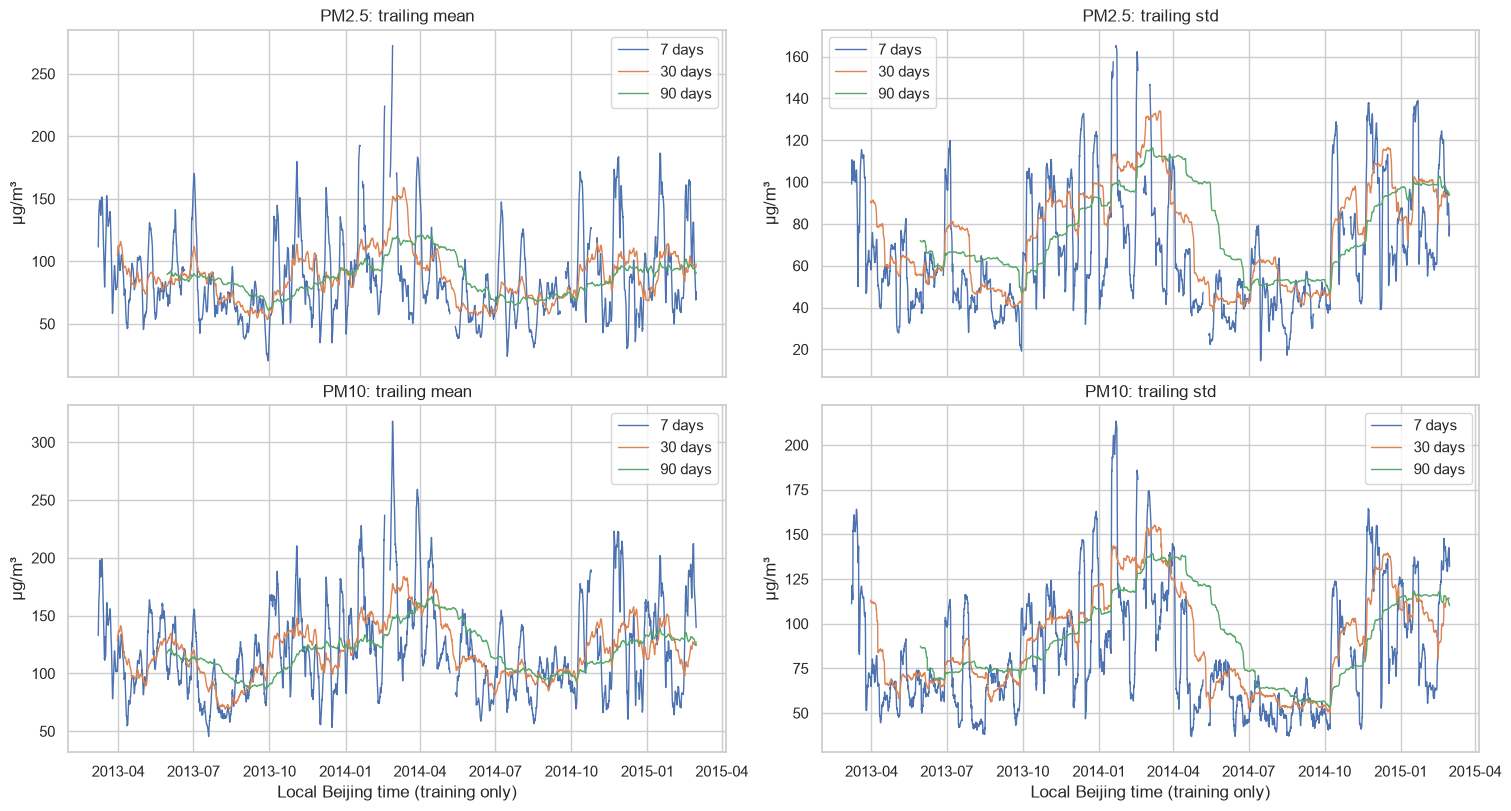

In [13]:
ROLLING_DAYS = [7, 30, 90]
MIN_OBSERVED_SHARE = 0.9
rolling_statistics = {}
rolling_rows = []

for target in TARGET_COLUMNS:
    for days in ROLLING_DAYS:
        window_hours = days * 24
        min_observations = int(np.ceil(MIN_OBSERVED_SHARE * window_hours))
        roller = train[target].rolling(window_hours, min_periods=min_observations, center=False)
        observed_count = train[target].rolling(window_hours, min_periods=0).count()
        full_window = pd.Series(np.arange(len(train)) >= window_hours - 1, index=train.index)
        retained = full_window & observed_count.ge(min_observations)
        stats = pd.DataFrame(
            {"mean": roller.mean().where(retained), "std": roller.std(ddof=1).where(retained),
             "observed_count": observed_count, "observed_share": observed_count / window_hours,
             "retained": retained}
        )
        assert stats.loc[~retained, ["mean", "std"]].isna().all().all()
        assert stats.loc[retained, "observed_count"].ge(min_observations).all()
        rolling_statistics[(target, days)] = stats
        rolling_rows.append(
            {"target": target, "window_days": days, "window_hours": window_hours,
             "minimum_observations": min_observations, "warmup_hours": window_hours - 1,
             "retained_windows": int(retained.sum()),
             "excluded_after_warmup": int((full_window & ~retained).sum()),
             "minimum_retained_observed_share": float(stats.loc[retained, "observed_share"].min()),
             "mean_min": stats["mean"].min(), "mean_max": stats["mean"].max(),
             "std_min": stats["std"].min(), "std_max": stats["std"].max()}
        )
rolling_summary = pd.DataFrame(rolling_rows).set_index(["target", "window_days"])
display(rolling_summary.round(3))

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, constrained_layout=True)
for row, target in enumerate(TARGET_COLUMNS):
    for col, statistic in enumerate(["mean", "std"]):
        ax = axes[row, col]
        for days in ROLLING_DAYS:
            stats = rolling_statistics[(target, days)]
            ax.plot(stats.index, stats[statistic], lw=1, label=f"{days} days")
        ax.set(title=f"{target}: trailing {statistic}", ylabel="µg/m³")
        ax.legend()
        if row == 1:
            ax.set_xlabel("Local Beijing time (training only)")
plt.show()


Shorter windows follow pollution episodes closely, while longer windows smooth them out and start later because their full windows must first elapse. Both targets show local means and standard deviations that change over time rather than flat curves (`rolling_summary`), which motivates the stationarity tests in notebook 02, although descriptive plots cannot prove non-stationarity or identify a differencing order.

The coverage rule exposes missing hours rather than filling them. Some short windows are excluded after warm-up, while longer windows can average over the same gaps and still meet the threshold, so retained windows can differ in coverage and missingness pattern.


## Carry the protocol into preprocessing

The exports below record the source checksum, selected station, split boundaries, package versions, the BIC candidate orders with the band-rule diagnostic, and the linear-fill sensitivity. They are written under `OUTPUT_DIR` and excluded from Git; the preprocessing notebook reloads the raw archive and restates the protocol, so it runs without this notebook's kernel or files.

The fill chosen in notebook 02 must be checked on the same training timestamps with `compare_filled_dependence(original, chosen_filled, max_lag)`, reporting `same_p`, both band-rule orders, the BIC order of the filled series, and the largest coefficient differences. If the BIC orders disagree, the gap-aware candidate stays the reference, the sensitivity is explained, and candidate feature spans are compared by temporal validation, never on the test interval. STL, Ljung–Box, and Granger in notebook 02 also need a documented filled series, and their dependence diagnostics are compared with the gap-aware reference here. The linear interpolation in this chapter is only a retrospective sensitivity experiment: it reads later training observations and is not a causal input policy for forecasting.


In [14]:
eda_output_dir = OUTPUT_DIR / "time_series_eda"
eda_output_dir.mkdir(parents=True, exist_ok=True)
eda_protocol = {
    **source_metadata, "targets": TARGET_COLUMNS, "covariates": COVARIATE_COLUMNS,
    "validation_start": VALIDATION_START.isoformat(), "test_start": TEST_START.isoformat(),
    "max_lag_by_target": MAX_LAG_BY_TARGET, "weekly_max_lag": WEEKLY_MAX_LAG,
    "order_rule": "BIC over AR(0..max_lag) by OLS on one common sample of complete lag windows",
    "bic_p": bic_selected_p, "aic_p": aic_selected_p, "bic_p_linear_fill": linear_filled_bic_p,
    "pacf_band_rule_diagnostic": "Last positive lag outside its own 1.96/sqrt(pair_counts) band, or 0",
    "p_gap": pacf_selected_p, "linear_sensitivity": linear_sensitivity,
    "notebook_02_chosen_fill_check": "performed in notebook 02 as chosen_fill_dependence_check",
    "package_versions": package_versions,
}
(eda_output_dir / "protocol.json").write_text(json.dumps(eda_protocol, indent=2, ensure_ascii=False), encoding="utf-8")
for target in TARGET_COLUMNS:
    gap_dependence[target].add_prefix("gap_").join(
        linear_dependence[target].add_prefix("linear_")
    ).to_csv(eda_output_dir / f"{target}_short_dependence.csv")
    weekly_gap_acf[target].add_prefix("gap_").join(
        weekly_linear_acf[target].add_prefix("linear_")
    ).to_csv(eda_output_dir / f"{target}_extended_acf.csv")
    information_criteria[target].to_csv(eda_output_dir / f"{target}_ar_information_criteria.csv")
split_summary.to_csv(eda_output_dir / "splits.csv")
dependence_summary.to_csv(eda_output_dir / "dependence_sensitivity.csv")
rolling_summary.to_csv(eda_output_dir / "rolling_summary.csv")
calendar_profile_table.to_csv(eda_output_dir / "calendar_profiles.csv")
calendar_effect_summary.to_csv(eda_output_dir / "calendar_effects.csv")
component_summary.to_csv(eda_output_dir / "component_summary.csv")
correlation_comparison.to_csv(eda_output_dir / "same_hour_correlations.csv", index=False)
print("Generated EDA evidence:", eda_output_dir)
print(eda_protocol["notebook_02_chosen_fill_check"])


Generated EDA evidence: D:\HCMUS\DataMining\preprocessing\outputs\time_series_eda
performed in notebook 02 as chosen_fill_dependence_check


## Sources and interpretation limits

- Dataset: Zhang et al. (2017), *Cautionary tales on air-quality improvement in Beijing*, Proceedings of the Royal Society A, [DOI: 10.1098/rspa.2017.0457](https://doi.org/10.1098/rspa.2017.0457); [UCI dataset 501](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data), [dataset DOI](https://doi.org/10.24432/C5RK5G), CC BY 4.0. The notebook prints its verified archive checksum and retains the original hourly measurements.
- Missing-data autocovariance: statsmodels [`acovf`](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.acovf.html), whose references include Parzen (1963), *On spectral analysis with missing observations and amplitude modulation*.
- PACF construction: statsmodels [`levinson_durbin`](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.levinson_durbin.html). The pair-adjusted covariance input and approximate pair-count bands are explicit choices in this chapter.
- Order selection: Schwarz (1978), *Estimating the dimension of a model*, Annals of Statistics 6(2), 461-464, [DOI: 10.1214/aos/1176344136](https://doi.org/10.1214/aos/1176344136); Akaike (1974), *A new look at the statistical model identification*, IEEE Transactions on Automatic Control 19(6), 716-723, [DOI: 10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705).
- Band interpretation: statsmodels [`plot_acf`](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html) distinguishes white-noise screening bands from Bartlett bands for raw-series ACF. This chapter uses the requested pair-count approximation and does not treat band crossings as corrected hypothesis tests.

These results concern one station and two training years. Station selection examined full-record missingness, so the selection procedure itself was not prospectively evaluated, and temporal dependence, clustered gaps, and possible changes in distribution limit what descriptive summaries can support. AI assisted the implementation and narrative; the student remains responsible for understanding and explaining the submitted methods. The [discussion chapter](report.md) records the broader reproducibility and completion limits.
